# Oxygen Optode Pipeline (Aanderaa) | Lag corrections

This notebook is the workspace for writing the code that processes dissolved oxygen measured on glider optodes, which will be integrated into the toolbox being developed at NOC within the GLIDERS - RISC project, called  [pelagos-py](https://github.com/NOC-OBG-Autonomy/pelagos-py). Only working with Aanderaa optodes for now. A separate notebook will be created for other optodes (e.g., SeaBird). 

This notebook is a follow up from `DO_Optode_dev.ipynb`, with a focus on the development of the lag corrections. All functions from `DO_Optode_dev.ipynb` have been moved into py files and are imported here. 

Start: 20260617

By: Elise Droste (elidro@noc.ac.uk)



***
# Resources

The processing steps are based on previous work in the DO optode community, as well as how it is done for BGC Argo. This is a list of links to consulted works and code: 

<b>Manuscripts</b>
- Bittig et al. (2018): https://www.frontiersin.org/journals/marine-science/articles/10.3389/fmars.2017.00429/full 
- Bittig & Körtzinger (2017)


<b>SOPs</b>
- Ocean Gliders SOPs: https://oceangliderscommunity.github.io/Oxygen_SOP/README.html
- Bittig et al. (2016): https://archimer.ifremer.fr/doc/00348/45915/ \ https://archimer.ifremer.fr/doc/00348/45915/56281.pdf
- IMOS Ocean Gliders Delayed Mode QA/QC Best Practice Manual: https://content.aodn.org.au/Documents/IMOS/Facilities/Ocean_glider/Delayed_Mode_QAQC_Best_Practice_Manual_OceanGliders_LATEST.pdf : Woo, L.M. and Gourcuff, C. (2023). Delayed Mode QA/QC Best Practice Manual Version 3.1 Integrated Marine Observing System. DOI: 10.26198/5c997b5fdc9bd (https://dx.doi.org/10.26198/5c997b5fdc9bd)

  DOI: https://dx.doi.org/10.26198/5c997b5fdc9bd
- Thierry et al. (2025), Argo Quality Control Manual: https://archimer.ifremer.fr/doc/00354/46542/
- Thierry et al. (2025a), Processing Argo Oxygen data at the DAC level: https://dx.doi.org/10.13155/39795 

<b>Code - Public</b>
- Ocean Gliders O2 SOP GitHub: https://github.com/OceanGlidersCommunity/Oxygen_SOP
- UEA Seagldier Toolbox: https://bitbucket.org/bastienqueste/uea-seaglider-toolbox/src/toolbox/
- Bittig et al. (2016): https://archimer.ifremer.fr/doc/00348/45915/
- GEOMAR Glider Toolbox: https://git.geomar.de/open-source/geomar_glider_toolbox

<b>Code - Private</b>
- Filipa Carvalho: matlab files. 
- Charlotte: matlab files.
- Pablo: matlab files. 

***
# Processing roadmap

A visualisation of the oxygen optode processing pipeline can be found here: 

https://www.figma.com/board/7bYMOu1zaj6fzAU1Ar2YQ8/Glider_DO_Optode_Pipeline?node-id=0-1&p=f&t=vkOw6Ba9V9yyuACe-0 

Where this fits in the overall pipeline can be found here: 

https://www.figma.com/board/9adA0ffM4Rr0zxeM6tzCvk/Standard-Glider-Processing?node-id=0-1&p=f&t=JqsBqmDLPoukYXvy-0 


***
# Packages

## Python packages

In [1]:
import numpy as np
import xarray as xr
import pandas as pd
import datetime
import gsw
import matplotlib.pyplot as plt
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

from IPython.core.interactiveshell import InteractiveShell 
InteractiveShell.ast_node_interactivity = "all" # allow multiple outputs from 1 cell


In [2]:
import importlib # To re-load modules after changes are made 

***
# General functions

Check if instance is array-like. 

In [3]:
def is_array_like(obj):
    return isinstance(obj, (np.ndarray, xr.DataArray, pd.Series, list, tuple))

Run data through a low-pass filter. <font color=orange> Code currently used in geometric alignment step, but I haven't yet finished coding that step! </font> 

In [4]:
from scipy.signal import butter, filtfilt

In [5]:
def lowpass_filter(data, cutoff, fs, order=3):
    """
    Apply Butterworth filter to smoothen dataset. It is a filtering method that does not distort the amplitude of low-frequency signals. 
    Removes high frequency noise/"spikes", but keeps slower trends. 
    
    ARGS:
        data: array-like
            Data to be passed through lowpass filter. Make sure NaNs are excluded! Filter cannot handle NaNs. Data also needs to have even spacing. 
        cutoff: float
            Cutoff frequency (i.e., the boundary between the slow and fast variations). Unit in Hz. 
        fs: float
            sampling frequency (measurements per unit. )
        order: 
            Filter order; sharpness of transition between pass and stop bands. Higher means a sharper cutoff, but can distort edges
    """
    # Cutoff (Wn) is normalised and must be between 0 adn 1. 
    b, a = butter(N = order, Wn = cutoff / (0.5 * fs), btype="low")
    return filtfilt(b, a, data) # filtfilt applies the filter forward and backward, so there is no time lag

***
# Data

Code is tested on data from the BioCarbon project. The data imported here is the output of the toolbox pipeline in the format in which it will be passed onto the optode pipeline. 

IDs of gliders: 
- Churchill 647
- Doombar 648
- Nelson 646
- Cabot 645


<s> Data imported here are data previously exported from the prototype toolbox pipeline in August 2025. </s>

<s> Data imported here are data run through the most up to date pipeline by Dan (20251202): </s>

Data imported here are the most up to date output from the pipeline by Dan/Orlando (20260617): 

In [6]:
%%bash

cd ../RISC_DO_Optode_rawdata/BIO_Carbon_20260617/

ls 

pwd

Cabot_645
Churchill_647
Doombar_648
Nelson_646
Recovery_ALR_4.nc
/Users/elidro/ED_Science/RISC_DO_Optode/RISC_DO_Optode_rawdata/BIO_Carbon_20260617


In [59]:
fdir = "../RISC_DO_Optode_rawdata/BIO_Carbon_20260617/Nelson_646/"
fname = "Nelson_646_R_Processed.nc" # "Nelson_646_processed_20251126.nc"
ds = xr.open_dataset(fdir + fname, decode_times=True)


In [9]:
np.unique(ds.SCI_PHASE)
np.unique(ds.PROFILE_DIRECTION)

array([1, 2, 3, 4, 5, 7])

array([-1.,  0.,  1., nan])

Check which optode-relevant variables have values in the dataset. 

In [10]:
optode_var_list = [  'DPHASE_DOXY',
                     'MOLAR_DOXY',
                     'TPHASE_DOXY',
                     "TCPHASE_DOXY", 
                     "CALPHASE_DOXY", 
                     "BPHASE_DOXY", 
                     'TEMP_DOXY',
                     'OXYSAT_DOXY',
                     'DPHASE_DOXY_QC',
                     'MOLAR_DOXY_QC',
                     'TPHASE_DOXY_QC',
                     'TEMP_DOXY_QC',
                     'OXYSAT_DOXY_QC', 
                      "CALPHASE_DOXY_QC", 
                     "TCPHASE_DOXY_QC", 
                     "BPHASE_DOXY_QC"]

In [11]:
print("Optode variables with only NaNs (True) or with data (False): ")
for var_name in optode_var_list:
    if var_name in ds.data_vars: 
        print(var_name, ds[var_name].isnull().all().item())
    else:
        print(var_name, " not found in variable list. ")

Optode variables with only NaNs (True) or with data (False): 
DPHASE_DOXY False
MOLAR_DOXY False
TPHASE_DOXY  not found in variable list. 
TCPHASE_DOXY  not found in variable list. 
CALPHASE_DOXY  not found in variable list. 
BPHASE_DOXY True
TEMP_DOXY  not found in variable list. 
OXYSAT_DOXY True
DPHASE_DOXY_QC False
MOLAR_DOXY_QC False
TPHASE_DOXY_QC  not found in variable list. 
TEMP_DOXY_QC  not found in variable list. 
OXYSAT_DOXY_QC False
CALPHASE_DOXY_QC  not found in variable list. 
TCPHASE_DOXY_QC  not found in variable list. 
BPHASE_DOXY_QC False


We have data:
- <s><b>BPHASE_DOXY</b>: Phase shift in blue excitatino light. Unit = degrees. <font color=pink> This will be the starting point of our calculations. </font></s>
- <b>DPHASE_DOXY</b>: calibrated phase measurement. Unit = degrees. <font color=pink> We re-calculate this ourselves (DPHASE = BPHASE). </font>
- <b>MOLAR_DOXY</b>: DO (dissolved oxygen concentration at zero pressure and in fresh water or at a reference salinity). Unit = umol L-1. These values are calculated by the instrument using manufacturer settings, but does not include a pressure correction on the phase shift. <font color=pink> We re-calculate this ourselves. </font>
- <b>OXYSAT_DOXY</b>: Oxygen saturation (percentage). Calculated using MOLAR_DOXY. <font color=pink> We re-calculate this ourselves. </font>

<font color=orange> <b>TEMP_DOXY</b>: Optode temperature measurements. Unit = degrees Celsius. Not found in dataset, but needed in calculations. </font> 

QC flags: 

In [12]:
np.unique(ds.BPHASE_DOXY_QC)
np.unique(ds.OXYSAT_DOXY_QC)
np.unique(ds.DPHASE_DOXY_QC)
np.unique(ds.MOLAR_DOXY_QC)

array([0], dtype=int8)

array([0], dtype=int8)

array([0], dtype=int8)

array([0], dtype=int8)

***
# Import optode settings

Set settings in _optode_pipeline_settings.py_, found in _settings_. 

In [13]:
# importlib.reload(optode_pipeline_settings)

In [14]:
from settings import optode_pipeline_settings

In [15]:
optode_pipeline_settings.Pcoef1

In [16]:
optode_pipeline_settings.uncal_phase_doxy
optode_pipeline_settings.calphase_doxy

'UNCAL_PHASE_DOXY'

'CAL_PHASE_DOXY'

***
# Load optode calibration sheet

In [17]:
ds.instrument # attribute containing list of instruments on the glider # no longer part of exported ds

['SBE Slocum Glider Payload (GPCTD) CTD',
 'WET Labs {Sea-Bird WETLabs} ECO Puck Triplet BB2FL-SLC scattering fluorescence sensor',
 'Oxygen optode 4831',
 'Photosynthetically Active Radiation sensor',
 'Slocum G1+G2 Glider Navigation data logger']

Instrument attribute does not contain information about the manufacturer of the optode, but we know it is Aanderaa. 

Both Churchill, Doombar, and Nelson have <font color=lightblue>Aanderaa 4831</font>. 


<div class="alert alert-block alert-warning">
<b>To do: </b> 
    
- [ ] Find a way to log the optode type, which is info required to make decisions along the processing tree
- [ ] Optode type in given cal sheets is 4831, but the data is what I'd expect for 3830.. i.e. BPHASE and DPHASE. 4831 would have TCPHASE/TPHASE and TC1/2RPHASE..
- [ ] Find correct calibration sheets for each glider ID. 
</div>

Glider calibration sheets for BIO-Carbon gliders: 

| Glider | SB   | CTD  | ECO puck   | PAR | Optode |
|---------|------|------|------------|-----|--------|
| 405     | 1117 | 9140 | BBCD: 3352 |     | 143    |
| 345     | 1097 | 9110 | BBCD: 3325 |     | 119    |
| 397     | 1087 | 9099 | BB2: 1611  | 459 | 144    |
| 398     | 1088 | 9100 | BBCD: 3289 | 461 | 286    |

### Sensor type

Manually set the optode type in the settings:

In [18]:
optode_pipeline_settings.sensor_type = "aa4831" # Unsure! I thought it was 4831, but that doesn't match what I'd expect from the variable names.. 

### Import calibration sheet

Calibration coefficients are saved in a subfolder, called _calibration_sheets_, which contains the data in py files that can be imported here. 

Add calibration data from the manufacturer in the appropriate calibration sheet, saved in dir _calibration_sheets_. 

In [19]:
from calibration_sheets import calibration_sheet_aa4831_397 as cal_sheet_aa

In [20]:
cal_sheet_aa.SVUFoilCoef0

AttributeError: module 'calibration_sheets.calibration_sheet_aa4831_397' has no attribute 'SVUFoilCoef0'

***
# Find starting conditions [READY]

## Find starting phase shift [READY]

<img src=markdown_pngs/optode_IMOS.png width="500"/>
[Optode optical design (Aanderaa, 2007; copied from Woo & Gourcurr, 2023 - IMOS)]


Aanderaa optodes measure a blue light and a red light excitation. The results of the blue and red phase shifts are used to calculate an uncalibrated phase shift, which will then be used to determine the calibrated phase shift: 


RED/BLUE &rarr; UNCALIBRATED PHASE SHIFT &rarr; (UNCALIBRATED PHASE SHIFT with pressure correction) &rarr; CALIBRATED PHASE SHIFT 


The naming of all of these phase shifts differs for different optode types!! Fun. Fun. Our aim here is to find which phase shift data are included in the dataset (for blue/red, uncalibrated, and calibrated phase shifts), and use the lowest level data we can find to calculate the rest, overwriting any higher level data that might already exist. To make things easier and more streamlined, we will refer and re-name where necessary the uncalibrated phase shift to UNCAL_PHASE_DOXY and calibrated phase shift to CALPHASE_DOXY. 

The next sections help us find which uncalibrated and calibrated phase shift data are available in the dataset. 

### Find uncalibrated phase shift (UNCAL_PHASE)

The blue/red and uncalibrated phase shifts appear in Aanderaa datasets, like so: 

<b>Aanderaa 3830 </b>

The uncalibrated phase (UNCAL_PHASE, i.e., uncalibrated for temperature) is the difference between the excitation measured from the blue (BPHASE) and red (RPHASE) light: 

$$UNCAL\_PHASE\_DOXY = BPHASE\_DOXY - RPHASE\_DOXY$$

However, RPHASE is often not used, so 

$$UNCAL\_PHASE\_DOXY = BPHASE\_DOXY$$

Thierry et al. (2025a): For 3830 optodes, UNCAL_Phase = BPhase.  

For Argo, they call uncalibrated phase PHASE, but this is too confusing, so I'm calling it UNCAL_PHASE_DOXY

<b>Aanderaa 4330</b>

The uncalibrated phase (TCPHASE) is the difference between the excitation measured from the blue (C1RPHASE) and red (C2RPHASE) light: 

$$TCPHASE\_DOXY = C1RPHASE - C2RPHASE$$

Thierry et al. (2025a): For 4330 optodes, Uncalibrated phase = TCPhase, named as TPHASE in Argo nomenclature. 

$$UNCAL\_PHASE\_DOXY = TCPHASE\_DOXY = TPHASE\_DOXY$$


--- 

<font color=pink>So, for Aanderaa3830, we need either BPHASE or UNCAL_PHASE to start with. For Aanderaa4330 we need either both C1RPHASE and C2RPHASE or TCPHASE to start with. </font>

---

Dataset might contain optode phase shift data at different "stages" of calculation, e.g., BPHASE_DOXY, UNCAL_PHASE_DOXY, DPHASE_DOXY, etc. 
Here run through data variables within the dataset and try to find the available uncalibrated optode phase shift data in this order: 

Aanderaa 3830:
1. BPHASE_DOXY and RPHASE_DOXY (uncalibrated) - RPHASE_DOXY often not used. 
2. UNCAL_PHASE_DOXY (uncalibrated)

Aanderaa 4330, 4835, and 4831: 
1. C1RPHASE and C2RPHASE
2. TCPHASE_DOXY (uncalibrated)
3. TPHASE_DOXY (uncalibrated) = C1RPHASE (blue) - C2RPHASE (red). This is the same as TCPHASE_DOXY! But TPHASE is the naming by Argo. 

---

<font color=pink> Side note: PHASE variable in dataset is the behaviour of the glider at sea, it has nothing to do with the optode. </font>  

Continue pipeline with the <i>lowest level phase shift</i> available. If that's blue/red phase, calculate the uncalibrated phase shift first. Then continue with a pressure correction on the uncalibrated phase shift (UNCAL_PHASE_PCORR), followed by converting it to a calibrated phase shift (CALPHASE_DOXY). If the calibrated phase shift is teh lowest level phase shift available, the pressure correction on the phase shift cannot be performed. We will then simply use the calibrated phase shift as given and continue to calculating the molar concentration. 

<div class="alert alert-block alert-warning">
<b>To do: </b> 

- [x] Include TPHASE! Which is uncal phase??? 
- [x] Lower priority: Add what the other variables are that we might find of other Aandereaa optodes, e.g. TPHASE and CALPHASE.
- [x] <s>Consider using a varying variable to accommodate different names for uncalibrated and calibrated phase shifts.</s> Done.
</div>

In [67]:
def find_uncalibrated_phase_optode_aa3830(ds, all_optode_phases_list, optode_pipeline_settings): 
    """
    Find uncalibrated optode phase shift data in dataset. Applicable to Aanderaa 3830 optodes. 
    """
    
    uncal_phase_found = ""
    raw_phase_names = ["BPHASE_DOXY", "UNCAL_PHASE_DOXY"]

    for phase_optode in raw_phase_names: 
        if phase_optode in all_optode_phases_list: # if phase exists in the dataset
            if bool(ds[phase_optode].isnull().all()): # check phase type contains only NaNs
                print(phase_optode, " exists but contains only NaNs.")
            else: # data exist! 
                if phase_optode == "BPHASE_DOXY": # if BPHASE, calculate CAL_PHASE
                    if "UNCAL_PHASE_DOXY" in ds.data_vars: # replace existing UNCAL_PHASE
                        ds["UNCAL_PHASE_DOXY"].values = ds[phase_optode].values # replaces values of array only, but keeps attributes of original array
                        print("UNCAL_PHASE_DOXY determined from: ", phase_optode, ".")
                        uncal_phase_found = phase_optode
                        optode_pipeline_settings.uncal_phase_doxy = "UNCAL_PHASE_DOXY" # set the uncalibrated phase shift variable 
                    else: # Create new UNCAL_PHASE variable based on BPHASE
                        ds["UNCAL_PHASE_DOXY"] = ds[phase_optode] # this keeps the attributes of the original PHASE array
                        # ds.assign(UNCAL_PHASE = ds.BPHASE) # this does not keep the attributes of the original BPHASE array
                        print("UNCAL_PHASE_DOXY determined from: ", phase_optode, ".")
                        uncal_phase_found = phase_optode
                        optode_pipeline_settings.uncal_phase_doxy = "UNCAL_PHASE_DOXY" # set the uncalibrated phase shift variable 
                    break # get out of loop
                    
                elif phase_optode == "UNCAL_PHASE_DOXY": 
                    print("UNCAL_PHASE_DOXY found and contains values. Continue with UNCAL_PHASE. ")
                    uncal_phase_found = phase_optode
                    optode_pipeline_settings.uncal_phase_doxy = "UNCAL_PHASE_DOXY" # set the uncalibrated phase shift variable 
                    break # get out of loop
    
                else:
                    uncal_phase_found = None

        else: 
            uncal_phase_found = None
        
    if uncal_phase_found == None: 
        print("No uncalibrated phase shift found. ")

    return uncal_phase_found
                   
    

In [68]:
def find_uncalibrated_phase_optode_aa4330(ds, all_optode_phases_list, optode_pipeline_settings): 
    """
    Find uncalibrated optode phase shift data in dataset. Applicable to Aanderaa 4330 optodes. 
    Change uncal_phase_doxy in settings according to lowest level of phase shift data found. 
    """
    
    uncal_phase_found = ""
    raw_phase_names = ["C1RPHASE", "C2RPHASE", "TCPHASE_DOXY", "TPHASE_DOXY"]

    for phase_optode in raw_phase_names: 
        if phase_optode in all_optode_phases_list: # if phase exists in the dataset
            if bool(ds[phase_optode].isnull().all()): # check phase type contains only NaNs
                print(phase_optode, " exists but contains only NaNs.")
            else: # data exist! 
                if phase_optode == "C1RPHASE": # if C1RPHASE, find C2RPHASE
                    if "C2RPHASE" not in ds.data_vars: 
                        print("C1RPHASE exists but C2RPHASE does not. Cannot calculate UNCAL_PHASE_DOXY. ")
                    else: 
                        if bool(ds["C2RPHASE"].isnull().all()): 
                            print("C1RPHASE exists, but C2RPHASE contains only NaNs. Cannot calculate UNCAL_PHASE_DOXY. ")
                        else: # calculate uncal_phase = c1rphase - c2rphase
                            ds["UNCAL_PHASE_DOXY"] = ds["C1RPHASE"] - ds["C2RPHASE"]
                            print("UNCAL_PHASE_DOXY calculated from C1RPHASE and C2RPHASE")
                            uncal_phase_found = "UNCAL_PHASE_DOXY"
                            optode_pipeline_settings.uncal_phase_doxy = "UNCAL_PHASE_DOXY" # set the uncalibrated phase shift variable 
                            break # get out of loop

                elif phase_optode == "C2RPHASE": # if C2RPHASE, find C1RPHASE
                    if "C1RPHASE" not in ds.data_vars: 
                        print("C2RPHASE exists but C1RPHASE does not. Cannot calculate UNCAL_PHASE_DOXY. ")
                    else: 
                        if bool(ds["C1RPHASE"].isnull().all()): 
                            print("C2RPHASE exists, but C1RPHASE contains only NaNs. Cannot calculate UNCAL_PHASE_DOXY. ")
                        else: # calculate uncal_phase = c1rphase - c2rphase
                            ds["UNCAL_PHASE_DOXY"] = ds["C1RPHASE"] - ds["C2RPHASE"]
                            print("UNCAL_PHASE_DOXY calculated from C1RPHASE and C2RPHASE")
                            uncal_phase_found = "UNCAL_PHASE_DOXY"
                            optode_pipeline_settings.uncal_phase_doxy = "UNCAL_PHASE_DOXY" # set the uncalibrated phase shift variable 
                            break # get out of loop
                        
                elif phase_optode == "TCPHASE_DOXY": 
                    ds["UNCAL_PHASE_DOXY"] = ds["TCPHASE_DOXY"]
                    print("TCPHASE_DOXY exists. Renamed to UNCAL_PHASE_DOXY.")
                    uncal_phase_found = "UNCAL_PHASE_DOXY"
                    optode_pipeline_settings.uncal_phase_doxy = "UNCAL_PHASE_DOXY" # set the uncalibrated phase shift variable 
                    break # get out of loop

                elif phase_optode == "TPHASE_DOXY": 
                    ds["UNCAL_PHASE_DOXY"] = ds["TPHASE_DOXY"]
                    print("TPHASE_DOXY exists. Renamed to UNCAL_PHASE_DOXY.")
                    uncal_phase_found = "UNCAL_PHASE_DOXY"
                    optode_pipeline_settings.uncal_phase_doxy = "UNCAL_PHASE_DOXY" # set the uncalibrated phase shift variable 
                    break # get out of loop
                    
                else:
                    uncal_phase_found = None

        else: 
            uncal_phase_found = None
        
    if uncal_phase_found == None: 
        print(phase_optode, " not found in data variables. ")

    return uncal_phase_found
    

<div class="alert alert-block alert-success">
STEP: Check if blue/red and/or uncalibrated phase shift data exist in dataset:
</div>

In [69]:
all_optode_phases_list = [v for v in ds.data_vars if ("PHASE" in v) & ("QC" not in v) ] # List all variable names containing "PHASE", exclude QC arrays
all_optode_phases_list = [v for v in all_optode_phases_list if v not in ("PHASE")] # Remove the PHASE variable (= glider behaviour)

find_uncalibrated_phase_optode_aa3830(ds, all_optode_phases_list, optode_pipeline_settings) 
find_uncalibrated_phase_optode_aa4330(ds, all_optode_phases_list, optode_pipeline_settings) # should run this, but variable names follow naming convention of 3830 series.. 

BPHASE_DOXY  exists but contains only NaNs.
No uncalibrated phase shift found. 
TPHASE_DOXY  not found in data variables. 


### Find calibrated phase shift (CALPHASE_DOXY)

If none of the uncalibrated phase shift data is included in the dataset, we need to look whether the calibrated phase shift data is available instead. 

The calibrated phase shift is calculated using the uncalibrated phase shift and a 4th order polynomial function using calibration coefficients provded by the manufacturer. 

These are the possible variable names for calibrated phase shift for all Aanderaa optodes:
1. DPHASE_DOXY (calibrated)
2. CALPHASE_DOXY (calibrated)

Note! If no uncalibrated phase shift data are available, then the pressure correction on the phase shift (next step) cannot be applied. 

In [70]:
def find_calibrated_phase_optode_aa(ds, all_optode_phases_list, optode_pipeline_settings): 
    """
    Find calibrated optode phase shift data in dataset. Can be applied to both Aanderaa 3830 and 4330 optodes. 
    """
    
    cal_phase_found = ""
    cal_phase_names = ["DPHASE_DOXY", "CALPHASE_DOXY"]

    for phase_optode in cal_phase_names: 
        if phase_optode in all_optode_phases_list: # if phase exists in the dataset
            if bool(ds[phase_optode].isnull().all()): # check phase type contains only NaNs
                print(phase_optode, " exists but contains only NaNs.")
            else: # data exist! 
                print(phase_optode, " found. ")
                ds["CALPHASE_DOXY"] = ds[phase_optode] # copy the calibrated phase shift and name it CALPHASE_DOXY for ongoing consistency
                cal_phase_found = phase_optode
                optode_pipeline_settings.calphase_doxy = "CALPHASE_DOXY" # set the calibrated phase shift variable 
                break # get out of loop
        else: 
            print("No calibrated phase shifts found. ")
            cal_phase_found = None
    
    if cal_phase_found == None: 
        print("No calibrated phase shift found. ")

    return cal_phase_found

<div class="alert alert-block alert-success">
STEP: Check if calibrated phase shift data (DPHASE_DOXY or CALPHASE_DOXY) exist in dataset:
</div>

In [71]:
all_optode_phases_list = [v for v in ds.data_vars if ("PHASE" in v) & ("QC" not in v) ] # List all variable names containing "PHASE", exclude QC arrays
all_optode_phases_list = [v for v in all_optode_phases_list if v not in ("PHASE")] # Remove the PHASE variable (= glider behaviour)

find_calibrated_phase_optode_aa(ds, all_optode_phases_list, optode_pipeline_settings)

DPHASE_DOXY  found. 


'DPHASE_DOXY'

### Find phase shift (combined)

The function below just combines the functions above and spits out the lowest level phase shift data found to use in subsequent calculations. 

In [72]:
def find_phase_optode_aa(ds, all_optode_phases_list, optode_pipeline_settings): 
    """
    Find which red/blue, uncalibrated, and calibrated phase shift data exist in the Aanderaa optode dataset. 
    """
    
    all_optode_phases_list = [v for v in ds.data_vars if ("PHASE" in v) & ("QC" not in v) ] # List all variable names containing "PHASE", exclude QC arrays
    all_optode_phases_list = [v for v in all_optode_phases_list if v not in ("PHASE")] # Remove the PHASE variable (= glider behaviour)
    
    if len(all_optode_phases_list) == 0: # If nothing has been found 
        print("No variables names containing PHASE found. Check naming conventions and dataset. ")

    else: 
        # Check if uncalibrated phase shift data are present
        if optode_pipeline_settings.sensor_type in ["aa4330", "aa4835", "aa4831"]: 
            uncal_phase_found = find_uncalibrated_phase_optode_aa4330(ds, all_optode_phases_list, optode_pipeline_settings)
        elif optode_pipeline_settings.sensor_type in ["aa3830", "aa3835", "aa3930", "aa3975", "aa4130", "aa4175"]: 
            uncal_phase_found = find_uncalibrated_phase_optode_aa3830(ds, all_optode_phases_list, optode_pipeline_settings)
        else: 
            uncal_phase_found = None
            print("Aanderaa sensor type not included in this pipeline. Uncalibrated phase shift data not found. ")

        # print(uncal_phase_found)
        if isinstance(uncal_phase_found, str): # if  uncalibrated phase shift data are present
            print("Uncalibrated phase shift found! Continue pipeline with ", uncal_phase_found, ". Next step: pressure correction. ")
            print("Settings updated for uncal_phase_doxy: ", optode_pipeline_settings.uncal_phase_doxy)
            
        else: # if uncalibrated phase shift data are not present, check for calibrated phase shift data
            cal_phase_found = find_calibrated_phase_optode_aa(ds, all_optode_phases_list, optode_pipeline_settings)
            
            if isinstance(cal_phase_found, str): 
                print("No uncalibrated phase shifts found, but found calibrated phase shift: ", cal_phase_found, ". Continue with this but skip pressure correction on phase shift.")
                print("Settings updated for calphase_doxy: ", optode_pipeline_settings.calphase_doxy)
            else: 
                print("No uncalibrated or calibrated phase shifts found. Check data variables. ")

    print("Check: uncalibrated phase shift (if used for next steps) is ", optode_pipeline_settings.uncal_phase_doxy, ".")
    print("Check: calibrated phase shift (if used for next steps) is ", optode_pipeline_settings.calphase_doxy, ".")


<div class="alert alert-block alert-success">
STEP: Check if/which uncalibrated or calibrated phase shift data exist in dataset:
</div>

In [73]:
find_phase_optode_aa(ds, all_optode_phases_list, optode_pipeline_settings)


TPHASE_DOXY  not found in data variables. 
DPHASE_DOXY  found. 
No uncalibrated phase shifts found, but found calibrated phase shift:  DPHASE_DOXY . Continue with this but skip pressure correction on phase shift.
Settings updated for calphase_doxy:  CALPHASE_DOXY
Check: uncalibrated phase shift (if used for next steps) is  UNCAL_PHASE_DOXY .
Check: calibrated phase shift (if used for next steps) is  CALPHASE_DOXY .


## Finding optode temperature [READY]

The optode also measures temperature: TEMP_DOXY. We will use these temperature measurements in some of the processing steps, depending on the optode type and version. 

Sometimes voltage of the thermistor is available. If so, we will use this to determine the temperature in degrees Celsius. 

In [28]:
from temp_doxy_voltage_to_degC_aa import temp_doxy_voltage_to_degC_aa

In [29]:
def check_for_temp_doxy(ds, cal_sheet_aa): 
    """
    Check whether TEMP_DOXY and TEMP_VOLTAGE_DOXY exist in the dataset (and contain data). 
    If TEMP_VOLTAGE_DOXY exists, calculate TEMP_DOXY using the manufacturer calibration coefficients. 
    This can override existing TEMP_DOXY data. 
    """

    temp_doxy_exist = "no"
    if "TEMP_DOXY" in ds.data_vars: 
        if ds["TEMP_DOXY"].isnull.all(): 
            print("TEMP_DOXY found in data variables, but containst no data.")
        else: 
            print("TEMP_DOXY found in data variables.")
            temp_doxy_exist = "yes"
    else: 
        print("TEMP_DOXY not found in data variables.")
    
    if "TEMP_VOLTAGE_DOXY" in ds.data_vars: 
        if ds.TEMP_VOLTAGE_DOXY.isnull.all(): 
            print("TEMP_VOLTAGE_DOXY found in data variables, but contains no data. ")
            if temp_doxy_exist == "yes": 
                print("No problem, just using TEMP_DOXY for further calculations. ")
        else:
            
            if temp_doxy_exist == "yes": 
                ds.TEMP_DOXY = temp_doxy_voltage_to_degC_aa3830(TEMP_VOLTAGE_DOXY, cal_sheet_aa)
                print("TEMP_VOLTAGE_DOXY found in data variables. Existing TEMP_DOXY has been overridden with newly calculated TEMP_DOXY.")
            else: 
                ds["TEMP_DOXY"] = temp_doxy_voltage_to_degC_aa3830(TEMP_VOLTAGE_DOXY, cal_sheet_aa)
                print("TEMP_VOLTAGE_DOXY found in data variables. New TEMP_DOXY has been calculated.")
    else: 
        if temp_doxy_exist == "no": 
            print("Neither TEMP_DOXY or TEMP_VOLTAGE_DOXY are found in data variables. Check dataset and naming conventions.")
        else: 
            print("TEMP_VOLTAGE_DOXY not found, but will use TEMP_DOXY for further calculations.")

<div class="alert alert-block alert-success">
STEP: Check if TEMP_DOXY or TEMP_VOLTAGE_DOXY are found in dataset:
</div>

In [30]:
check_for_temp_doxy(ds, cal_sheet_aa)

TEMP_DOXY not found in data variables.
Neither TEMP_DOXY or TEMP_VOLTAGE_DOXY are found in data variables. Check dataset and naming conventions.


<div class="alert alert-block alert-warning">

TEMP_DOXY is not available in the dataset. Create a fake TEMP_DOXY based on CTD temperature (TEMP) for now.  

<b>To do: </b> 

- [ ] Replace temporary TEMP_DOXY with actual TEMP_DOXY
</div>

Since TEMP_DOXY is not available, we will here create a fake TEMP_DOXY variable, just so we can test code. 

Before doing so, we need to mask some values, because the DPHASE_DOXY variable contains quite a few zeros:

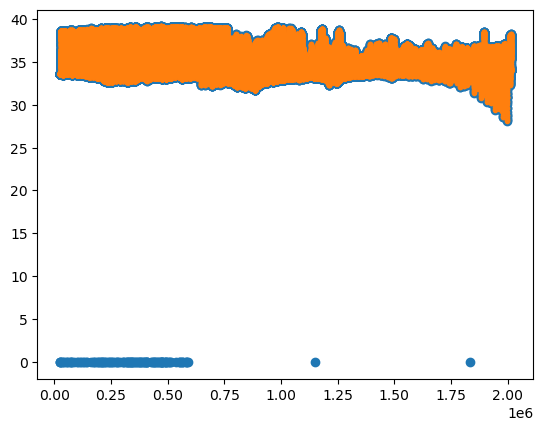

In [31]:
plt.scatter(ds.N_MEASUREMENTS, ds.DPHASE_DOXY)
plt.scatter(ds.N_MEASUREMENTS.where(ds.DPHASE_DOXY > 0), ds.DPHASE_DOXY.where(ds.DPHASE_DOXY > 0), marker = ".");

In [32]:
ds["DPHASE_DOXY"] = ds.DPHASE_DOXY.where(ds.DPHASE_DOXY > 0)
# ds["DPHASE_DOXY_QC"] = ds.DPHASE_DOXY_QC.where(ds.DPHASE_DOXY > 0, 4) # update QC accordingly

In [33]:
ds = ds.set_coords("TIME").swap_dims({"N_MEASUREMENTS": "TIME"}) # make time a coordinate and swap dimensions ie make dimension time
optode_meas_times = ds.TIME.where(~ds.DPHASE_DOXY.isnull(), drop = True) # find times when optode measurements were made 
temp_interp_onto_optode = ds.TEMP.interp(TIME = optode_meas_times) # interpolate TEMP onto these exact times
ds["TEMP_DOXY"] = temp_interp_onto_optode # copy interpolated CTD temperature measurements and pretend they're the optode's measurements 

ds = ds.swap_dims({"TIME": "N_MEASUREMENTS"}) # swap back


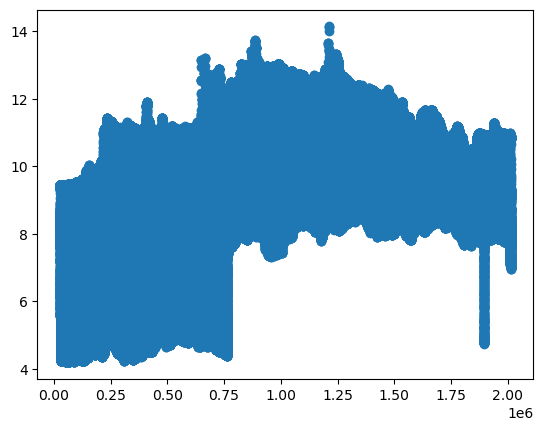

In [34]:
plt.scatter(ds["N_MEASUREMENTS"], ds["TEMP_DOXY"]);

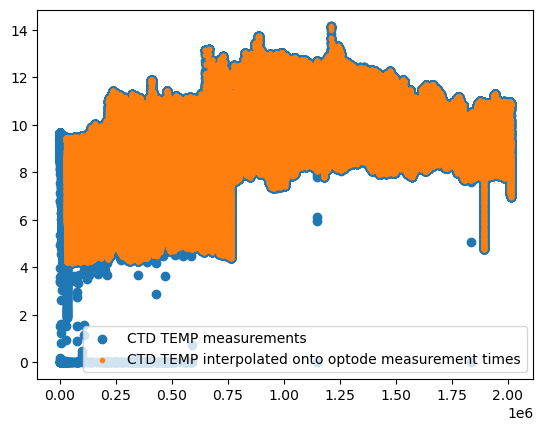

In [35]:
plt.scatter(ds["N_MEASUREMENTS"], ds["TEMP"], label = "CTD TEMP measurements")
plt.scatter(ds["N_MEASUREMENTS"], ds["TEMP_DOXY"], label = "CTD TEMP interpolated onto optode measurement times", marker = ".")
plt.legend();

***
# Geometrically align CTD to optode [IN PROGRESS]

<div class="alert alert-block alert-info">
<b>Required input:  </b>
    
- geo_time_lag

<b>Optional input:  </b>

- distance between optode and CTD on glider (in cm)
- PROFILE_GRADIENT (glider dive rate)
- SCI_PHASE (glider pitch)

<b> Other requirements: </b>

- CTD data needs to have gone through QC
- Can only use CTD data flagged as "good"

</div>

_Notes_

PROFILE_GRADIENT is the vertical velocity (gradient) and is calculated by pelagos-py as depth change divided by time change. This is the same as the dive rate. What we need for the lag correction is the glider's velocity of travel, which is the dive rate divided by the sin of the glider pitch. 

We require CTD data for the next processing steps. However, since the CTD and optode sensors are not located in the same space on the glider, there's a time lag between the two. So we need to shift CTD data to align with the optode in space and in time, i.e., geometrically. 

<img src=markdown_pngs/glider_geo_shift.png width="500"/>
[Glider orientation during descent (copied from Woo & Gourcurr, 2023 - IMOS)]


The geometic lag time ($\tau$) to travel the distance between the Optode and the CTD recorder is calculated as:

$$\tau = \frac{d}{v}$$

where ($d$) is the distance between the sensors (default of 90 cm) and ($v$) is the glider's velocity of travel, which is given by:

$$v = \frac{r}{\sin(\theta)}$$

$r$ is the dive rate (m/s) and ($\theta$) is the glider pitch (degrees).

---

This can be done in two ways: 

1. <b>Use a default geometric time lag from Woo et al. (2023).</b>

   a) Shift CTD data, incl. depth, in time to align with optode measurements.

   b) Interpolate shifted CTD data incl. depth for optode measurement times.

   c) Make sure to add shifted depth and interpolated CTD data to original CTD variables.
   
2. <b>Use calculated geometric time lag based on distance between optode and CTD on the glider, glider dive rate, and glider pitch. </B>

   a) Calculate geometric time lag per up and down cast using the mean dive rate and pitch per cast.

   b) Filter geometric time lag through low pass filter (separately for up and down casts).

   c) Shift CTD data incl. depth accordingly.

   d) Interpolate shifted CTD data incl. depth for optode measurement times. 

   e) Make sure to add shifted depth and interpolated CTD data to the original CTD variables. 



<div class="alert alert-block alert-warning">
Have not implemented this yet!! 

To do: 

- [x] For now, just interpolate CTD data onto times when optode data is available. Just so I can continue with the calculations and fix this later
- [x] Replace temporary "fake" geometric shift CTD data with actual adjusted CTD data! 
- [x] Implement the default option geometric lag. 
- [ ] Add the second option, which is to calculate the geometric lag from glider pitch and vertical velocity.
- [x] Add dive rate function. = vertical gradient! Already calculated by pelagos-py. 
- [x] Do we have a variable that differentiates up and down casts? YES: PROFILE_DIRECTION and SCI_PHASE
- [ ] Test low-pass filter: adjust settings? Check the Ocean Glider manual once I regain access to it. 

</div>



## Mean per up/down cast

Up and down casts can be identified by either PROFILE_DIRECTION or SCI_PHASE variables. 

PROFILE_DIRECTION: -1 on upcast, 1 on downcast, 0 for any parking/surfacing etc... NaN if it's unknown (shouldn't be much NaN, but probably a few per file)

SCI_PHASE: 

(from [OG format user manual - vocabulary Collection](https://github.com/OceanGlidersCommunity/OG-format-user-manual/blob/main/vocabularyCollection/phase.md): )

| id | phase | description | status |
|:----- |:----- |:------ |:------ |
| 0 | unknown | when the platform phases described below do not fit the platform behavior, or when the behavior of the platform is unknown | pending |
| 1 | ascent | the platform is commanded to move upward - climbing | pending |
| 2 | descent | the platform is commanded to move downward - diving | pending |
| 3 | surfacing | the platform is performing a surfacing maneuver or is at the surface for communication, recovery or safety purpose | pending |
| 4 | parking | the platform is maintained at a parking or hover depth, not moving relative to the water | pending |
| 5 | inflection | the platform is below the surface and is changing from ascent to descent or descent to ascent | pending |
| 6 | propelled | the platform is moving laterally, parallel to the water surface, using propellers/thrusters| pending |
| 7 | transition | the platform is changing from one of the defined phases to another defined phase | pending |



In [142]:
def calc_mean_per_cast(ds, cast_id_var, var): 
    """
    Calculate the mean of a given variable per cast. 

    ARGS:
        var : string
            Name of variable in the dataset. 
        cast_id_var : string
            Name of variable that indicates up/down casts. Should be either "SCI_PHASE" or "PROFILE_DIRECTION" or "PROFILE_NUMBER" 

    RETURN: 
        mean_per_cast = Pandas DataFrame
            Mean of variable per cast. 

    Note: 
        PROFILE_NUMBER -1 and 0 are excluded!
    """ 

    # Cleanest way to do this is to use Pandas dataframes
    df = ds[[cast_id_var, "PROFILE_NUMBER", var]].to_dataframe().reset_index()
    if cast_id_var== "SCI_PHASE": 
        
        df = df.loc[df.SCI_PHASE.isin([1, 2])] # Select only data that have SCIPHASE == 1 or SCIPHASE == -1, i.e., excluding 3, 4, 5, 6, 7
        mean_per_cast = df.groupby([df.PROFILE_NUMBER, df.SCI_PHASE])[var].mean().unstack().reset_index() # Calculate mean of variable per cast 
        mean_per_cast.rename(columns = {1: "upcast", 2: "downcast"}, inplace = True)
        
    elif cast_id_var == "PROFILE_DIRECTION":

        df = df.loc[df.PROFILE_DIRECTION.isin([-1, 1])] # Select only data that have SCIPHASE == 1 or SCIPHASE == -1, i.e., excluding 0 and NaNs
        mean_per_cast = df.groupby([df.PROFILE_NUMBER, df.PROFILE_DIRECTION])[var].mean().unstack().reset_index() # Calculate mean of variable per cast 
        mean_per_cast.rename(columns = {-1: "upcast", 1: "downcast"}, inplace = True)

    elif cast_id_var == "PROFILE_NUMBER": 
        
        mean_per_cast = df.groupby(df.PROFILE_NUMBER)[var].mean().reset_index() # Calculate mean of variable per cast 
        
    else:
        print("set cast_id_var to either SCI_PHASE or PROFILE_DIRECTION or PROFILE_NUMBER")
        
    # < 20260617 - NOC - ED - commented 
    # # Calculate mean time per cast
    # mean_time_per_cast = ds["TIME"].groupby(ds.PROFILE_NUMBER.where(ds.PROFILE_NUMBER > 0)).mean() # PROFILE_NUMBER -1 and 0 are excluded! 

    # # Calculate mean of variable per cast
    # mean_var_per_cast = ds[var].groupby(ds.PROFILE_NUMBER.where(ds.PROFILE_NUMBER > 0)).mean() # TO DO: replace profile_number with cast (up/down)
        
    # # Assign mean time to mean variable 
    # mean_var_per_cast = mean_var_per_cast.assign_coords(TIME=mean_time_per_cast)
    # 20260617 - NOC - ED > 


    # Sort by time: necessary? 
    # mean_var_per_cast = mean_var_per_cast.sortby("TIME")


    return mean_per_cast
    

## Smoothing

In [143]:
def lowpass_filter(data, cutoff, fs, order=3):
    """
    Apply Butterworth filter to smoothen dataset. It is a filtering method that does not distort the amplitude of low-frequency signals. 
    Removes high frequency noise/"spikes", but keeps slower trends. 
    
    ARGS:
        data: array-like
            Data to be passed through lowpass filter. Make sure NaNs are excluded! Filter cannot handle NaNs. Data also needs to have even spacing. 
        cutoff: float
            Cutoff frequency (i.e., the boundary between the slow and fast variations). Unit in Hz. 
        fs: float
            sampling frequency (measurements per unit. )
        order: 
            Filter order; sharpness of transition between pass and stop bands. Higher means a sharper cutoff, but can distort edges
    """
    # Cutoff (Wn) is normalised and must be between 0 adn 1. 
    # b, a = butter(N = order, Wn = cutoff / (0.5 * fs), btype="low")
    b, a = butter(N = order, Wn = 1 / cutoff, btype="low", fs = fs)
    return filtfilt(b, a, data) # filtfilt applies the filter forward and backward, so there is no time lag

Test phase

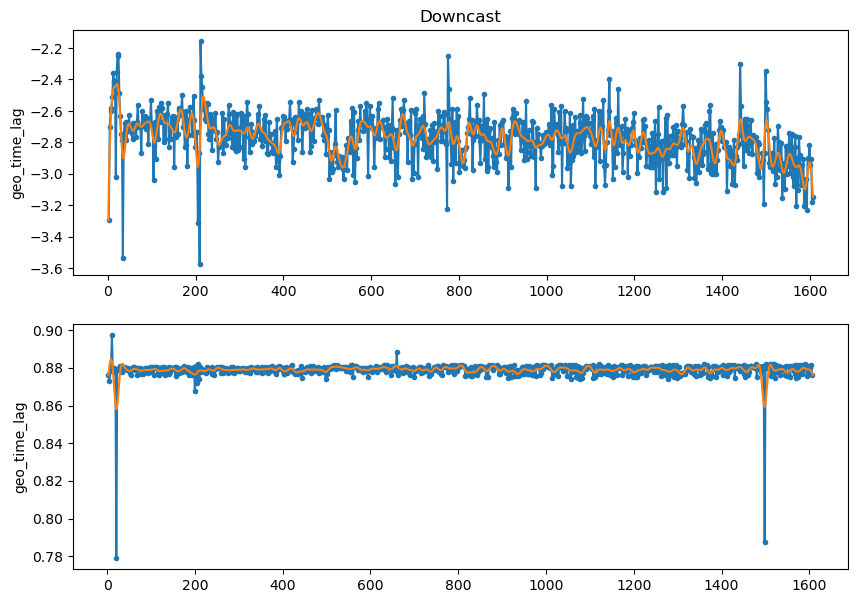

In [145]:
# Using profile_direction first 
d = 90 # distance between optode and ctd [cm]

# Calculate means per cast for pitch, profile vertical gradient, and time
df_meancast_pitch = calc_mean_per_cast(ds, cast_id_var = "PROFILE_DIRECTION", var = "GLIDER_PITCH")
df_meancast_vertgradient = calc_mean_per_cast(ds, cast_id_var = "PROFILE_DIRECTION", var = "PROFILE_GRADIENT")
df_meancast_time = calc_mean_per_cast(ds, cast_id_var = "PROFILE_DIRECTION", var = "TIME")

# Combine data for the down cast and for the up cast
df_mean_downcast = pd.concat([df_meancast_pitch[["PROFILE_NUMBER", "downcast"]].rename(columns = {"downcast": "pitch"}), 
                            df_meancast_vertgradient[["downcast"]].rename(columns = {"downcast": "vert_gradient"}), 
                           df_meancast_time[["downcast"]].rename(columns = {"downcast": "time"})], axis = 1)
df_mean_downcast = df_mean_downcast.loc[~df_mean_downcast["time"].isna()].reset_index()

df_mean_upcast = pd.concat([df_meancast_pitch[["PROFILE_NUMBER", "upcast"]].rename(columns = {"upcast": "pitch"}), 
                          df_meancast_pitch[["upcast"]].rename(columns = {"upcast": "vert_gradient"}), 
                           df_meancast_time[["upcast"]].rename(columns = {"upcast": "time"})], axis = 1)
df_mean_upcast = df_mean_upcast.loc[~df_mean_upcast["time"].isna()].reset_index()

# Calculate geometric time lag per up and down cast using the mean dive rate and pitch per cast.
df_mean_downcast["velocity_of_travel"] = df_mean_downcast["vert_gradient"] / np.sin(df_mean_downcast["pitch"]) # Calculate vertical velocity per cast
df_mean_upcast["velocity_of_travel"] = df_mean_upcast["vert_gradient"] / np.sin(df_mean_upcast["pitch"]) # Calculate vertical velocity per cast

df_mean_downcast["geo_time_lag"] =  (d/100) / df_mean_downcast["velocity_of_travel"] # Calculate geometric time lag per cast
df_mean_upcast["geo_time_lag"] =  (d/100) / df_mean_upcast["velocity_of_travel"] # Calculate geometric time lag per cast

# Reformat time variable
# ref_time = np.datetime64('2024-05-28T12:40:45.521514752')
# df_mean_downcast["TIME_reformatted"] = ref_time + df_mean_downcast["time"].astype("timedelta64[ns]")
# df_mean_upcast["TIME_reformatted"] = ref_time + df_mean_upcast["time"].astype("timedelta64[ns]")


# Fill NaNs for time lag
df_mean_downcast["geo_time_lag_fill"] = df_mean_downcast["geo_time_lag"].ffill().bfill()
df_mean_upcast["geo_time_lag_fill"] = df_mean_upcast["geo_time_lag"].ffill().bfill()

# Pass through filter - using profile number, not time
# Wn = 1 / cutoff
fs = 1 # 1 samples per profile
cutoff = 10 # remove changes faster than every 5 profiles
# Digital filter critical frequencies must be 0 < Wn < fs/2 (fs=1.0 -> fs/2=0.5)

df_mean_downcast["geo_time_lag_fill_filt"] = lowpass_filter(data = df_mean_downcast["geo_time_lag_fill"], cutoff = cutoff, fs = fs) # pass data through low-pass filter 
df_mean_upcast["geo_time_lag_fill_filt"] = lowpass_filter(data = df_mean_upcast["geo_time_lag_fill"], cutoff = cutoff, fs = fs) # pass data through low-pass filter 

# Combine based on profile_number
df_mean_cast_geolag = pd.concat([df_mean_downcast[["PROFILE_NUMBER", "geo_time_lag_fill_filt"]], df_mean_upcast[["PROFILE_NUMBER", "geo_time_lag_fill_filt"]]]).sort_values("PROFILE_NUMBER")

# Display data 
fig = plt.figure(figsize = (10, 7))
ax0 = fig.add_subplot(211)
ax1 = fig.add_subplot(212)
ax0.scatter(df_mean_downcast.PROFILE_NUMBER, df_mean_downcast.geo_time_lag, marker = "."); 
ax0.plot(df_mean_downcast.PROFILE_NUMBER, df_mean_downcast.geo_time_lag_fill)
ax0.plot(df_mean_downcast.PROFILE_NUMBER, df_mean_downcast.geo_time_lag_fill_filt)

ax1.scatter(df_mean_upcast.PROFILE_NUMBER, df_mean_upcast.geo_time_lag, marker = ".")
ax1.plot(df_mean_upcast.PROFILE_NUMBER, df_mean_upcast.geo_time_lag_fill)
ax1.plot(df_mean_upcast.PROFILE_NUMBER, df_mean_upcast.geo_time_lag_fill_filt)

ax0.set_ylabel("geo_time_lag")
ax1.set_ylabel("geo_time_lag")
ax0.set_title("Downcast");

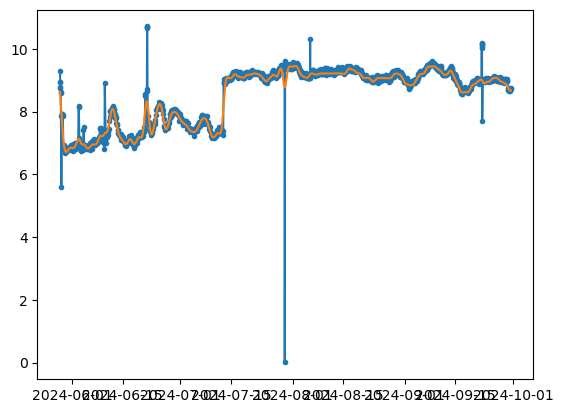

In [191]:
# df_temp_meancast = calc_mean_per_cast(ds, cast_id_var = "SCI_PHASE", var = "TEMP")
# df_temp_meancast = calc_mean_per_cast(ds, cast_id_var = "PROFILE_DIRECTION", var = "TEMP")
df_meancast_temp = calc_mean_per_cast(ds, cast_id_var = "PROFILE_NUMBER", var = "TEMP")
df_meancast_time = calc_mean_per_cast(ds, cast_id_var = "PROFILE_NUMBER", var = "TIME")

df_meancast = pd.merge(df_meancast_temp, df_meancast_time)

mean_var_per_cast = mean_var_per_cast.swap_dims({"PROFILE_NUMBER": "TIME"})
regular = mean_var_per_cast.resample(TIME="1s").interpolate("linear")
regular_filled = regular.ffill("TIME").bfill("TIME")

fs = 1 # 1 samples per sec
cutoff = 1/(3600 * (24*2)) # remove changes faster than every 24 hours
geo_time_lag_filt = lowpass_filter(data = regular_filled, cutoff = cutoff, fs = fs) # pass data through low-pass filter 

plt.scatter(mean_var_per_cast.TIME, mean_var_per_cast, marker = ".")
plt.plot(regular_filled.TIME, regular_filled)
plt.plot(regular_filled.TIME, geo_time_lag_filt); 

## Dive rate [NOT WRITTEN]

<font color=orange> No need, toolbox takes care of this already: data stored in PROFILE_GRADIENT </font> 

In [ ]:
# def calculate_dive_rate(depth, time): 
#     """
#     Calculate the dive rate of the glider. 


#     ARGS: 
#         depth : Array-like
#             Depth of glider in m. 
#         time : Array-like
#             Time variable

#     RETURN:
#         dive_rate : Array-like
#             Dive rate i.e. vertical velocity of the glider in the water column. 
            
#     """
#     print("Code yet to be written. ")
#     # return dive_rate

## Derive geometric lag

In [194]:
# def derive_geometric_time_lag(ds, dive_rate, pitch, d=None): 
#     """
#     Derive geometric time lag between DO optode and CTD based on dive rate and pitch, using mean dive rate and pitch per cast. 
#     Following Woo & Gourcurr (2023) - IMOS. 
    
#     ARGS: 
#         dive_rate: array-like
#             Dive rate data. Required input if time_lag == "derive". Unit in m s-1. Default = None. 
#         pitch: array-like
#             Pitch measurements. Required input if time_lag == "derive". Unit in deg. Default = None. 
#         d: float
#             Distance between the CTD and the DO optode on the glider. Unit in cm. 
#     RETURN: 
#         geo_time_lag_filt : array-like
#             Geometric time lag between OD optode and CTD (smoothed). Unit in s. 
            
#     """

#     # Find distance between CTD and DO optode (d)
#     if isinstance(d, float): 
#         print("Using following given distance between CTD and DO optode: ", d, " cm.")
#     else: 
#         d = 90 
#         print("Using default distance between CTD and DO optode: ", d, " cm.")

#     # Calculate the vertical velocity of travel (v)
#     if (isinstance(dive_rate, float)) & (isinstance(pitch, float)): # TO DO : remove part between if and else later - not usable
#         print("Using dive rate = ", dive_rate, "m s-1 and pitch = ", pitch, "deg in vertical velocity calculation. ")
#         # ds["DIVE_RATE"] = calculate_dive_rate(depth, time) # calculate the dive rate
#     else: 
#         # a) Calculate geometric time lag per up and down cast using the mean dive rate and pitch per cast.
#         mean_dive_rate_per_cast = calc_mean_per_cast(ds, var = "DIVE_RATE") # Calculate mean dive rate per cast 
#         mean_pitch_per_cast = calc_mean_per_cast(ds, var = "GLIDER_PITCH") # Calculate mean pitch per cast 

#         mean_vert_vel_per_cast = mean_dive_rate_per_cast / np.sin(mean_pitch_per_cast) # Calculate vertical velocity per cast
#         mean_geo_time_lag = d / mean_vert_vel_per_cast # Calculate geometric time lag per cast

#         # Interpolate geo time lag onto regular time grid 
#         mean_geo_time_lag = mean_geo_time_lag.swap_dims({"PROFILE_NUMBER": "TIME"}) # set TIME as dimension
#         mean_geo_time_lag_interp = mean_geo_time_lag.resample(TIME = "1s").interpolate("linear") # interpolate onto regular grid 
#         mean_geo_time_lag_interp = mean_geo_time_lag_interp.ffill("TIME").bfill("TIME") # fill NaNs at edges (filter doesn't like NaNs)

#         # b) Filter geometric time lag through low pass filter (separately for up and down casts). -- TO TEST 
#         fs = 1 # 1 sample per s
#         cutoff = 1/(3600*12) # remove changes faster than every 12 hours - TO DO: CHECK IF THIS NEEDS ADJUSTING
#         geo_time_lag_filt_interp = lowpass_filter(data = mean_geo_time_lag_interp, cutoff = cutoff, fs = fs) # pass data through low-pass filter 

#         # Interpolate back onto original time frame/grid 
#         geo_time_lag_filt = geo_time_lag_filt_interp.interp(TIME=geo_time_lag_filt.TIME)

#     return geo_time_lag_filt

In [193]:
def derive_geometric_time_lag(ds, cast_id_var = "PROFILE_DIRECTION", d=90): 
    """
    Derive geometric time lag between DO optode and CTD based on dive rate and pitch, using mean dive rate and pitch per cast. 
    Following Woo & Gourcurr (2023) - IMOS. 
    
    ARGS: 
        cast_id_var: str
            Variable name indicating up or down casts: SCI_PHASE or PROFILE_DIRECTION. Default = PROFILE_DIRECTION. 
        d: float
            Distance between the CTD and the DO optode on the glider. Unit in cm. 
    RETURN: 
        lag_lookup : Pandas dict
            dict containing mean geometric time lag between OD optode and CTD (smoothed) for every up and down cast ie PROFILE_NUMBER. Unit in s. 
            
    """
    if cast_id_var not in ["SCI_PHASE", "PROFILE_DIRECTION"]: 
        print("cast_id_var argument must be either SCI_PHASE or PROFILE_DIRECTION.")
        df_mean_cast_geolag = None
        
    else: 
    
        # Find distance between CTD and DO optode (d)
        if isinstance(d, float): 
            print("Using following given distance between CTD and DO optode: ", d, " cm.")
        else: 
            d = 90 
            print("Using default distance between CTD and DO optode: ", d, " cm.")
    
        
        # Calculate means per cast for pitch, profile vertical gradient, and time
        df_meancast_pitch = calc_mean_per_cast(ds, cast_id_var = cast_id_var, var = "GLIDER_PITCH")
        df_meancast_vertgradient = calc_mean_per_cast(ds, cast_id_var = cast_id_var, var = "PROFILE_GRADIENT")
        df_meancast_time = calc_mean_per_cast(ds, cast_id_var = cast_id_var, var = "TIME")
        
        # Combine data for the down cast and for the up cast
        df_mean_downcast = pd.concat([df_meancast_pitch[["PROFILE_NUMBER", "downcast"]].rename(columns = {"downcast": "pitch"}), 
                                    df_meancast_vertgradient[["downcast"]].rename(columns = {"downcast": "vert_gradient"}), 
                                   df_meancast_time[["downcast"]].rename(columns = {"downcast": "time"})], axis = 1)
        df_mean_downcast = df_mean_downcast.loc[~df_mean_downcast["time"].isna()] # remove all rows that are not downcast, indicated by NaNs

        df_mean_upcast = pd.concat([df_meancast_pitch[["PROFILE_NUMBER", "upcast"]].rename(columns = {"upcast": "pitch"}), 
                                  df_meancast_pitch[["upcast"]].rename(columns = {"upcast": "vert_gradient"}), 
                                   df_meancast_time[["upcast"]].rename(columns = {"upcast": "time"})], axis = 1)
        df_mean_upcast = df_mean_upcast.loc[~df_mean_upcast["time"].isna()] # remove all rows that are not upcast, indicated by NaNs


        # Calculate geometric time lag per up and down cast using the mean dive rate and pitch per cast.
        df_mean_downcast["velocity_of_travel"] = df_mean_downcast["vert_gradient"] / np.sin(df_mean_downcast["pitch"]) # Calculate vertical velocity per cast
        df_mean_upcast["velocity_of_travel"] = df_mean_upcast["vert_gradient"] / np.sin(df_mean_upcast["pitch"]) # Calculate vertical velocity per cast
        
        df_mean_downcast["geo_time_lag"] =  (d/100) / df_mean_downcast["velocity_of_travel"] # Calculate geometric time lag per cast
        df_mean_upcast["geo_time_lag"] =  (d/100) / df_mean_upcast["velocity_of_travel"] # Calculate geometric time lag per cast
                
        # Fill NaNs for time lag
        df_mean_downcast["geo_time_lag_fill"] = df_mean_downcast["geo_time_lag"].ffill().bfill()
        df_mean_upcast["geo_time_lag_fill"] = df_mean_upcast["geo_time_lag"].ffill().bfill()
        
        # Pass through filter - using profile number, not time
        # Wn = 1 / cutoff
        fs = 1 # 1 samples per profile
        cutoff = 10 # remove changes faster than every 5 profiles
        # Digital filter critical frequencies must be 0 < Wn < fs/2 (fs=1.0 -> fs/2=0.5)
        
        df_mean_downcast["geo_time_lag_fill_filt"] = lowpass_filter(data = df_mean_downcast["geo_time_lag_fill"], cutoff = cutoff, fs = fs) # pass data through low-pass filter 
        df_mean_upcast["geo_time_lag_fill_filt"] = lowpass_filter(data = df_mean_upcast["geo_time_lag_fill"], cutoff = cutoff, fs = fs) # pass data through low-pass filter 

        # Combine based on profile_number
        df_mean_cast_geolag = pd.concat([df_mean_downcast[["PROFILE_NUMBER", "geo_time_lag_fill_filt"]], df_mean_upcast[["PROFILE_NUMBER", "geo_time_lag_fill_filt"]]]).sort_values("PROFILE_NUMBER")

        
        # Display data 
        fig = plt.figure(figsize = (10, 7))
        ax0 = fig.add_subplot(211)
        ax1 = fig.add_subplot(212)
        ax0.scatter(df_mean_downcast.PROFILE_NUMBER, df_mean_downcast.geo_time_lag, marker = ".", label = "per cast"); 
        ax0.plot(df_mean_downcast.PROFILE_NUMBER, df_mean_downcast.geo_time_lag_fill, label = "NaNs interpolated")
        ax0.plot(df_mean_downcast.PROFILE_NUMBER, df_mean_downcast.geo_time_lag_fill_filt, label = "low-pass filter")
        
        ax1.scatter(df_mean_upcast.PROFILE_NUMBER, df_mean_upcast.geo_time_lag, marker = ".", label = "per cast")
        ax1.plot(df_mean_upcast.PROFILE_NUMBER, df_mean_upcast.geo_time_lag_fill, label = "NaNs interpolated")
        ax1.plot(df_mean_upcast.PROFILE_NUMBER, df_mean_upcast.geo_time_lag_fill_filt, label = "low-pass filter")
        
        ax0.set_ylabel("geo_time_lag")
        ax1.set_ylabel("geo_time_lag")
        ax0.set_title("Downcast")
        ax1.set_title("Upcast")
        
        ax0.legend()
        ax1.legend(); 

        # Create a lookup dictionary 
        lag_lookup = (
            df_mean_cast_geolag
            .set_index("PROFILE_NUMBER")["geo_time_lag_fill_filt"]
            .to_dict()
        )


    return lag_lookup



Using default distance between CTD and DO optode:  90  cm.


PROFILE_DIRECTION,PROFILE_NUMBER,geo_time_lag_fill_filt
0,1.0,-3.296564
1,2.0,-3.065538
2,3.0,0.876032
3,4.0,-2.856368
4,5.0,0.880122
...,...,...
1603,1604.0,0.878295
1604,1605.0,-3.056661
1605,1606.0,0.877287
1606,1607.0,-3.145247


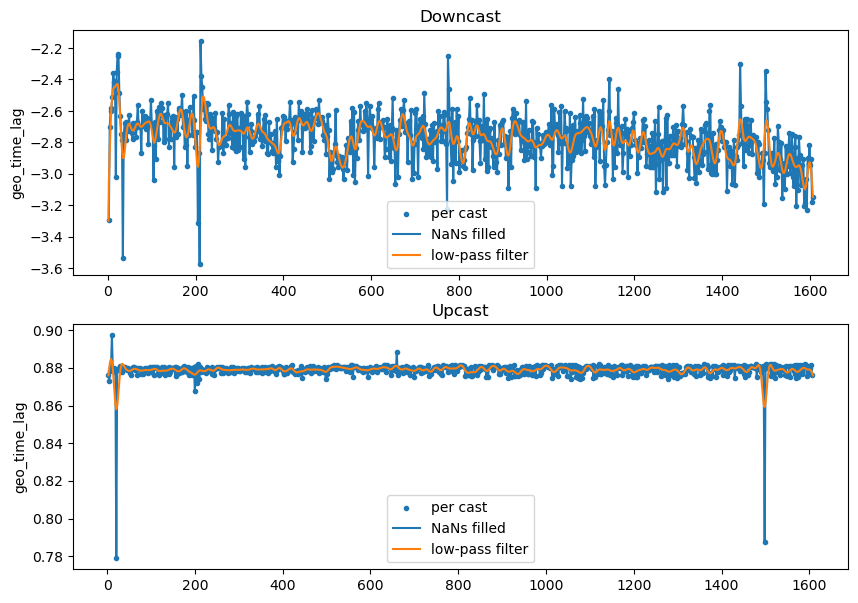

In [148]:
derive_geometric_time_lag(ds = ds, cast_id_var = "PROFILE_DIRECTION", d=90)

## Align CTD to optode

In [194]:
def align_ctd_to_optode(ds, ctd_vars, optode_var, geo_time_lag): 

    ds_ = ds.swap_dims({"N_MEASUREMENTS": "TIME"}) # Set time as the dimension for the CTD variable; reindex on time dimension. Note that this also promotes TIME as a coordinate  
        
    if optode_var is None:
        raise KeyError(
            f"None of {optode_vars} were found or had valid (non-NaN) data. Unable to align CTD to optode measurements."
        )
    else: 
        print(f"Using '{optode_var}' to define optode sampling times.")
        optode_time = ds_[optode_var].dropna(dim = "TIME").TIME.sortby("TIME") # Find timestamps when optode has measurements
        shifted_time = optode_time - pd.to_timedelta(geo_time_lag, unit = "s") # Shift optode time 

    if optode_time.sizes["TIME"] == 0: # No optode measurements
        return xr.Dataset()
    
    else:

        aligned = {}
    
        for var in ctd_vars:
    
            ctd_var = ds_[var].dropna("TIME").groupby("TIME").first().sortby("TIME") # Find timestamps when ctd has measurements and remove any duplicates which would mess up the interpolation 
    
            # Interpolate the CTD data onto the shifted optode times
            interp = (
                ctd_var
                .interp(TIME=shifted_time)
                .assign_coords(TIME=optode_time)
                .reindex(TIME=ds_.TIME) # this step intends to make the aligned variable have exactly the same TIME coordinate as ds_, which should allow merging the interpolated data with the original dataset
                .swap_dims({"TIME": "N_MEASUREMENTS"})
                .reset_coords("TIME", drop=True) # Remove TIME as coordinate because ds does not have TIME as a coordinate and so it will cause problems merging otherwise. 
            )
    
            aligned[f"{var}_ALIGNED"] = interp
    
            if shifted_time.min().values < ctd_var.TIME.min().values:
                print(f"'{var}': minimum shifted_time is lower than CTD time range. These data points will be NaN in aligned '{var}' data.")
            else: 
                print(f"'{var}': minimum shifted_time is within CTD time range.")
            if shifted_time.max().values > ctd_var.TIME.max().values:
                print(f"'{var}': maximum shifted_time is higher than CTD time range. These data points will be NaN in aligned '{var}' data.")
            else:
                print(f"'{var}': maximum shifted_time is within CTD time range. ")
    
        ds_with_ctd_aligned = ds.assign(aligned) # Merge with the original dataset
    
        return ds_with_ctd_aligned

## Align CTD to optode - custom lag [INCOMPLETE]

<font color=orange> TO DO: adapt according to pelagos-py geometric shift convo with ChatGPT: change the helper function etc. with purpose to avoid NaNs because optode shifted times are out of CTD time range </font> 

In [201]:
def align_ctd_to_optode_dynamic(ds, optode_vars, ctd_vars, d, cast_id_var = "PROFILE_DIRECTION"): 
    """
    Apply linear time shift using (filtered) geometric time lag. 
    ARGS: 
        ...

    RETURN:
        Geometrically aligned variables within ctd_vars_to_align 
    """

    optode_var = find_var_with_data(ds, var_candidates = optode_vars) # Find optode data with values
    
    geo_lag_lookup = derive_geometric_time_lag(ds = ds, cast_id_var = cast_id_var, d = d) # Calculate the geometric time lag per cast

    aligned = []
    for profile, profile_ds in ds.groupby("PROFILE_NUMBER"): # Run through each profile_number, which is sequential for both down and up casts
        print("------------------------------")
        print(f"PROFILE_NUMBER = '{profile}'")
    
        geo_lag = lag_lookup.get(profile) # Find the corresponding geometric time lag value
    
        if geo_lag is None:
            geo_lag = 0
            print(f"No geometric time lag found for PROFILE_NUMBER '{profile}'")
    
        aligned.append(align_ctd_to_optode(ds = profile_ds, ctd_vars = ctd_vars, optode_var = optode_var, geo_time_lag = geo_lag))

    aligned_ds = xr.concat(aligned, dim="N_MEASUREMENTS")
    aligned_ds = aligned_ds.sortby(["N_MEASUREMENTS"])
    
    return aligned_ds


Using default distance between CTD and DO optode:  90  cm.
------------------------------
PROFILE_NUMBER = '1.0'
Using 'CALPHASE_DOXY' to define optode sampling times.
------------------------------
PROFILE_NUMBER = '2.0'
Using 'CALPHASE_DOXY' to define optode sampling times.
------------------------------
PROFILE_NUMBER = '3.0'
Using 'CALPHASE_DOXY' to define optode sampling times.
------------------------------
PROFILE_NUMBER = '4.0'
Using 'CALPHASE_DOXY' to define optode sampling times.
------------------------------
PROFILE_NUMBER = '5.0'
Using 'CALPHASE_DOXY' to define optode sampling times.
------------------------------
PROFILE_NUMBER = '6.0'
Using 'CALPHASE_DOXY' to define optode sampling times.
------------------------------
PROFILE_NUMBER = '7.0'
Using 'CALPHASE_DOXY' to define optode sampling times.
------------------------------
PROFILE_NUMBER = '8.0'
Using 'CALPHASE_DOXY' to define optode sampling times.
------------------------------
PROFILE_NUMBER = '9.0'
Using 'CALPHASE

<xarray.Dataset> Size: 134MB
Dimensions:                                  (N_MEASUREMENTS: 72454, N_PARAM: 24)
Dimensions without coordinates: N_MEASUREMENTS, N_PARAM
Data variables: (12/124)
    TIME                                     (N_MEASUREMENTS) datetime64[ns] 580kB ...
    TIME_GPS                                 (N_MEASUREMENTS) datetime64[ns] 580kB ...
    PHASE                                    (N_MEASUREMENTS) float32 290kB n...
    PHASE_QC                                 (N_MEASUREMENTS) float32 290kB n...
    CNDC                                     (N_MEASUREMENTS) float32 290kB n...
    PRES                                     (N_MEASUREMENTS) float32 290kB n...
    ...                                       ...
    MOLAR_DOXY_ADJUSTED                      (N_MEASUREMENTS) float32 290kB n...
    MOLAR_DOXY_ADJUSTED_QC                   (N_MEASUREMENTS) float32 290kB n...
    CALPHASE_DOXY                            (N_MEASUREMENTS) float32 290kB n...
    PRES_ALIGNED                             (N_MEASUREMENTS) float64 580kB n...
    PRAC_SALINITY_ADJUSTED_ALIGNED           (N_MEASUREMENTS) float64 580kB n...
    TEMP_ALIGNED                             (N_MEASUREMENTS) float64 580kB n...

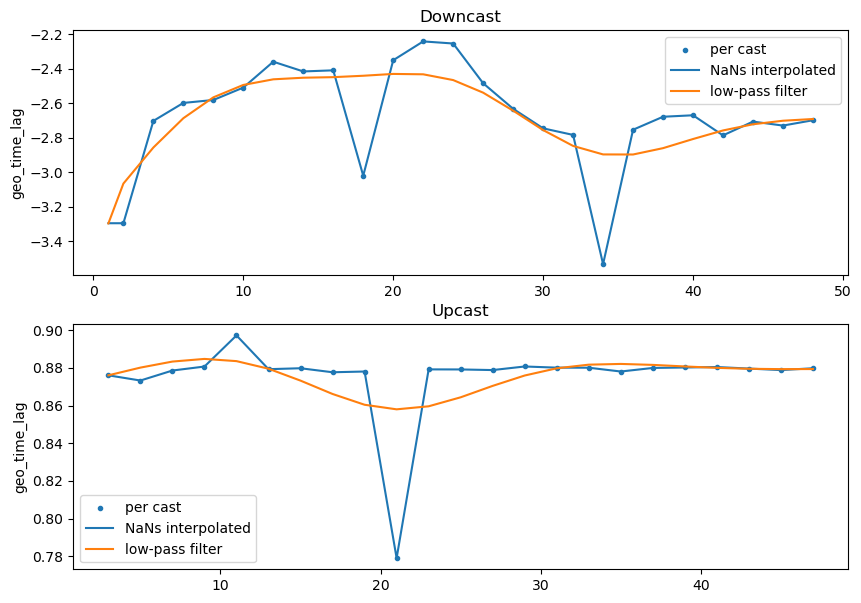

In [202]:
ctd_vars = ["PRES", "PRAC_SALINITY_ADJUSTED", "TEMP"]
geo_time_lag = 3.9450
optode_vars = [optode_pipeline_settings.uncal_phase_doxy, optode_pipeline_settings.calphase_doxy, "MOLAR_DOXY"]
cast_id_var = "PROFILE_DIRECTION"

align_ctd_to_optode_dynamic(ds = ds.isel(N_MEASUREMENTS=slice(1, 100000)), optode_vars = optode_vars, ctd_vars = ctd_vars, d = d, cast_id_var = cast_id_var)

## Align CTD to optode - default lag

In [623]:
# def align_ctd_to_optode_constant(ds, ctd_vars, geo_time_lag):

#     ds_alignment = ds.swap_dims({"N_MEASUREMENTS": "TIME"}).copy() # set time as the dimension for the CTD variable; reindex on time dimension
    
#     # Find timestamps when optode has measurements
#     if "MOLAR_DOXY" in ds_alignment.data_vars: # MOLAR_DOXY should be in NRT and DM datafiles! Unlike the uncal and calphase, which might not be. 
#         optode = ds_alignment["MOLAR_DOXY"] 
#         optode_time = optode.where(~optode.isnull(), drop = True).TIME.sortby("TIME") # find optode time points ie where data exists
#         shifted_optode_time = optode_time - pd.to_timedelta(geo_time_lag, unit = "s") # np.timedelta64(int(geo_time_lag * 1e9), "ns") caused values to drop! # subtract the geometric time lag from optode times

#     else: 
#         print(optode_pipeline_settings.uncal_phase_doxy,  " not found in data variables. Set uncalibrated phase shift in settings or check data.")

#     ctd_var_alignment_dict = {}
    
#     for ctd_var in ctd_vars: 
#         ctd_var_array = ds_alignment[ctd_var] # select the array 
#         # ctd_var_array = ctd_var_array.swap_dims({"N_MEASUREMENTS": "TIME"}) # set time as the dimension for the CTD variable; reindex on time dimension
#         ctd_var_available = ctd_var_array.where(~ctd_var_array.isnull(), drop = True) # find times when CTD variable has been measured. This is to remove any duplicate time points. 
#         ctd_var_available = ctd_var_available.sortby("TIME") # sort times (required for interp)

#         ctd_var_interp = ctd_var_available.interp(TIME = shifted_optode_time.values) # interpolate CTD onto the shifted time - requires unique time 
#         ctd_var_interp = ctd_var_interp.assign_coords(TIME = optode_time)# keep the interpolated values, but assign the original times (ie optode time)
        
#         # add aligned variable into the dataset
#         ctd_var_interp = ctd_var_interp.reindex(TIME = ds_alignment.TIME)
#         ds_alignment = ds_alignment.assign(**{f"{ctd_var}_ALIGNED": ctd_var_interp})

#         ctd_var_alignment_dict[ctd_var + "_ALIGNED"] = ds_alignment[ctd_var + "_ALIGNED"].swap_dims({"TIME": "N_MEASUREMENTS"}) # add aligned variables to the dictionary
#         print(ctd_var, " done: ", ctd_var + "_ALIGNED")
        
#     return ctd_var_alignment_dict



In [40]:
def find_var_with_data(ds, var_candidates): 
    return next(                  
        (
            var for var in var_candidates # run through the list of available oxygen data
            if var in ds.data_vars and ds[var].notnull().any().item() # check if it exists in the dataset and whether it contains data
        ),
        None,
    ) 

In [127]:
def calculate_alignment_metrics(ds, var, aligned_var, geo_time_lag):

    # Select only times where both measurements exist
    valid = (
        ds[var].notnull()
        & ds[aligned_var].notnull()
    )

    var_og = ds[var].where(valid, drop=True)
    aligned = ds[aligned_var].where(valid, drop=True)

    difference = var_og - aligned # Calculate the difference

    metrics = {
        "lag_seconds": geo_time_lag,
        "n_points_compared": int(valid.sum()),
        "nan_fraction_aligned": float(ds[aligned_var].isnull().mean()),
        "mean_difference": float(difference.mean()),
        "std_difference": float(difference.std()),
        "rmse": float(np.sqrt((difference**2).mean())),
        "correlation": float(
            np.corrcoef(
                var_og.values,
                aligned.values
            )[0, 1]
        ),
    }

    return metrics

In [155]:
def align_ctd_to_optode_constant(ds, ctd_vars, optode_vars, geo_time_lag): 
    
    optode_var = find_var_with_data(ds, var_candidates = optode_vars) # Find optode data with values


    # ds_ = ds.swap_dims({"N_MEASUREMENTS": "TIME"}) # Set time as the dimension for the CTD variable; reindex on time dimension. Note that this also promotes TIME as a coordinate  
    
    # if optode_var is None:
    #     raise KeyError(
    #         f"None of {optode_vars} were found or had valid (non-NaN) data. Unable to align CTD to optode measurements."
    #     )
    # else: 
    #     print(f"Using '{optode_var}' to define optode sampling times.")
    #     optode_time = ds_[optode_var].dropna(dim = "TIME").TIME.sortby("TIME") # Find timestamps when optode has measurements
    #     shifted_time = optode_time - pd.to_timedelta(geo_time_lag, unit = "s") # Shift optode time 

    # aligned = {}

    # for var in ctd_vars:

    #     ctd_var = ds_[var].dropna("TIME").groupby("TIME").first().sortby("TIME") # Find timestamps when ctd has measurements and remove any duplicates which would mess up the interpolation 

    #     # Interpolate the CTD data onto the shifted optode times
    #     interp = (
    #         ctd_var
    #         .interp(TIME=shifted_time)
    #         .assign_coords(TIME=optode_time)
    #         .reindex(TIME=ds_.TIME) # this step intends to make the aligned variable have exactly the same TIME coordinate as ds_, which should allow merging the interpolated data with the original dataset
    #         .swap_dims({"TIME": "N_MEASUREMENTS"})
    #         .reset_coords("TIME", drop=True) # Remove TIME as coordinate because ds does not have TIME as a coordinate and so it will cause problems merging otherwise. 
    #     )

    #     aligned[f"{var}_ALIGNED"] = interp

    #     if shifted_time.min().values < ctd_var.TIME.min().values:
    #         print(f"'{var}': minimum shifted_time is lower than CTD time range. These data points will be NaN in aligned '{var}' data.")
    #     else: 
    #         print(f"'{var}': minimum shifted_time is within CTD time range.")
    #     if shifted_time.max().values > ctd_var.TIME.max().values:
    #         print(f"'{var}': maximum shifted_time is higher than CTD time range. These data points will be NaN in aligned '{var}' data.")
    #     else:
    #         print(f"'{var}': maximum shifted_time is within CTD time range. ")

    # ds_with_ctd_aligned = ds.assign(aligned) # Merge with the original dataset

    
    ds_with_ctd_aligned = align_ctd_to_optode(ds = ds, ctd_vars = ctd_vars, optode_var = optode_var, geo_time_lag = geo_time_lag)

    # Print statistics
    for var in ctd_vars:
        ds_with_ctd_aligned_ = ds_with_ctd_aligned.dropna(dim="N_MEASUREMENTS", subset=[optode_var]) # Only include data points where optode measurements exist
        alignment_metrics = calculate_alignment_metrics(ds = ds_with_ctd_aligned_, var = var, aligned_var = f"{var}_ALIGNED", geo_time_lag = geo_time_lag)

        print("-----------------")
        print(f"Alignment summary for '{var}': ")
        print("-----------------")
        print(f"Lag applied:          {alignment_metrics['lag_seconds']:.4f} s")
        print(f"Points compared:      {alignment_metrics['n_points_compared']}")
        print(f"NaN fraction:         {alignment_metrics['nan_fraction_aligned']:.4%}")
        print(f"Mean difference:      {alignment_metrics['mean_difference']:.5f}")
        print(f"Std difference:       {alignment_metrics['std_difference']:.5f}")
        print(f"RMSE:                 {alignment_metrics['rmse']:.5f}")
        print(f"Correlation:          {alignment_metrics['correlation']:.4f}")

        
    return  ds_with_ctd_aligned# xr.Dataset(aligned)



In [157]:
def plot_geo_alignment(ds, var_og, var_aligned): 
    
    fig = plt.figure(figsize = (15, 5))
    ax0 = fig.add_subplot(131)
    ax1 = fig.add_subplot(132)
    ax2 = fig.add_subplot(133)
    
    ax0.scatter(ds.TIME, ds[var_og], label = var_og)
    ax0.scatter(ds.TIME, ds[var_aligned], label = var_aligned)
    ax0.legend()
    
    ax1.scatter(ds[var_og], ds[var_aligned], c = ds.PRES)
    ax1.set_xlabel(var_og)
    ax1.set_ylabel(var_aligned)
    
    ax2.scatter(ds.TIME, ds[var_og]-ds[var_aligned], c = ds.PRES)
    ax2.set_ylabel(var_og + " - " + var_aligned)
    
    fig.tight_layout();



Using 'CALPHASE_DOXY' to define optode sampling times.
'PRES': minimum shifted_time is within CTD time range.
'PRES': maximum shifted_time is within CTD time range. 
'PRAC_SALINITY_ADJUSTED': minimum shifted_time is within CTD time range.
'PRAC_SALINITY_ADJUSTED': maximum shifted_time is within CTD time range. 
'TEMP': minimum shifted_time is within CTD time range.
'TEMP': maximum shifted_time is within CTD time range. 
-----------------
Alignment summary for 'PRES': 
-----------------
Lag applied:          3.9 s
Points compared:      460696
NaN fraction:         0.00%
Mean difference:      0.003
Std difference:       0.459
RMSE:                 0.459
Correlation:          1.000
-----------------
Alignment summary for 'PRAC_SALINITY_ADJUSTED': 
-----------------
Lag applied:          3.9 s
Points compared:      460697
NaN fraction:         0.00%
Mean difference:      0.000
Std difference:       0.012
RMSE:                 0.012
Correlation:          1.000
-----------------
Alignment su

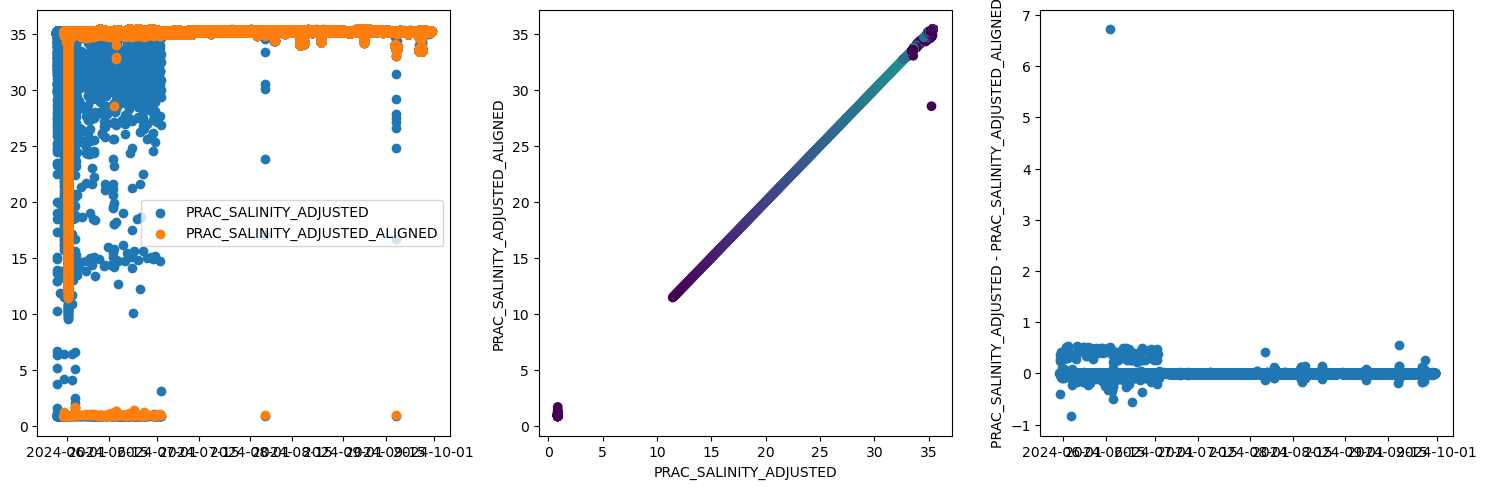

In [156]:
ctd_vars = ["PRES", "PRAC_SALINITY_ADJUSTED", "TEMP"]
geo_time_lag = 3.9450
optode_vars = [optode_pipeline_settings.uncal_phase_doxy, optode_pipeline_settings.calphase_doxy, "MOLAR_DOXY"]
ds_with_ctd_aligned = align_ctd_to_optode_constant(ds = ds, ctd_vars = ctd_vars, optode_vars = optode_vars, geo_time_lag = 3.9450)
plot_geo_alignment(ds = ds_with_ctd_aligned, var_og = "PRAC_SALINITY_ADJUSTED", var_aligned = "PRAC_SALINITY_ADJUSTED_ALIGNED")

## Apply geometrical alignment of CTD to optode

In [624]:
def align_ctd_to_optode(ds, geo_time_lag = 3.9450, dive_rate = None, pitch = None, d = 90):
    """
    Geometrical alignment
    Adjust CTD data to optode location by correcting for geometric lag (seconds). 
    Default time_lag (3.9450) from IMOS Ocean Gliders Delayed Mode QA/QC Best Practice Manual:
    https://content.aodn.org.au/Documents/IMOS/Facilities/Ocean_glider/Delayed_Mode_QAQC_Best_Practice_Manual_OceanGliders_LATEST.pdf

    ARGS:
        geo_time_lag: float or string
            Either time in seconds used to shift CTD measurements to align with optode position, or string ("derive") that indicates the time shift will be derived based on dive_rate and pitch. Default = 3.9450.
            Should be positive if CTD is in front of the optode, negative if optode is in front of the CTD. 
        dive_rate: array-like or float
            Dive rate data. Required input if time_lag == "derive". Unit in m s-1. Default = None. 
        pitch: array-like or float
            Pitch measurements. Required input if time_lag == "derive". Unit in deg. Default = None. 
        d: float
            Distance between the CTD and the DO optode on the glider. Unit in cm. Default = 90. 

    RETURN:
        shifted phase shift or CTD data? TO DO 
        
    """
    
    # Check if necessary variables are present in the dataset. -- TODO
    ctd_vars = ["PRES", "PRAC_SALINITY", "TEMP"]
    ctd_vars_to_align = []

    for ctd_var in ctd_vars: 
        if ctd_var not in ds.data_vars: 
            print(ctd_var, " not found in variable names. Geometric alignment with optode is not applied to this variable. ")
        else: 
            if bool(ds[ctd_var].isnull().all()): 
                print(ctd_var, " contains only NaNs. Geometric alignment with optode is not applied to this variable. ")
            else:                 
                print("Geometric alignment will be applied to ", ctd_var)
                ctd_vars_to_align.append(ctd_var)

    # Find the geo_time_lag
    if isinstance(geo_time_lag, float): 
        print("Using following time lag to adjust CTD data for geometric lag: ", geo_time_lag, " s.")
        ds = align_ctd_to_optode_constant(ds, ctd_vars, optode_vars, geo_time_lag)
        plot_geo_alignment(ds = ds_with_ctd_aligned, var_og = "PRAC_SALINITY_ADJUSTED", var_aligned = "PRAC_SALINITY_ADJUSTED_ALIGNED")
        plot_geo_alignment(ds = ds_with_ctd_aligned, var_og = "TEMP", var_aligned = "TEMP_ALIGNED")
        plot_geo_alignment(ds = ds_with_ctd_aligned, var_og = "PRES", var_aligned = "PRES_ALIGNED")
    elif geo_time_lag == "derive": 
        # geo_time_lag_derived = derive_geometric_time_lag(ds, dive_rate = None, pitch = None, d=None)
        # align_ctd_to_optode_geometric_custom(ds, ctd_vars_to_align, dive_rate = None, pitch = None, d = 90)
        print("Using following time lag derived from vertical velocity and pitch: ", geo_time_lag_derived, " s. NOT YET IMPLEMENTED. ")
    else:
        geo_time_lag = 3.9450
        print("WARNING: input invalid for geometric lag correction. Using default of ", geo_time_lag, " s.")

    # Shift CTD variables and depth  with time_lag - IMOS applies it to BPAHSE... 
    # ctd_vars_to_align # only apply to the CTD vars that exist and contain data 
    apply_geometrical_alignment(ds, geo_time_lag, ctd_vars_to_align)
    


<div class="alert alert-block alert-success">
STEP: Align CTD data to optode measurement times:
</div>

In [625]:
ctd_optode_geometrical_alignment(ds = ds, geo_time_lag = 3.9450, dive_rate = None, pitch = None, d = None)


Geometric alignment will be applied to  PRES
Geometric alignment will be applied to  PRAC_SALINITY
Geometric alignment will be applied to  TEMP
Using default time lag to adjust CTD data for geometric lag:  3.945  s.
PRES  done:  PRES_ALIGNED
PRAC_SALINITY  done:  PRAC_SALINITY_ALIGNED
TEMP  done:  TEMP_ALIGNED


## Temporary "fake" geometrically-aligned variables

Just creating fake CTD variables that are used as placeholders for geometrically-aligned measurements. 

<font color=orange> All CTD data used for optode data processing from here onward use these placeholder data!! </font> 

<div class="alert alert-block alert-warning">
<b>To do: </b> 

- [x] Replace this temporary measure with actual geometrically shifted CTD data!! 
</div>

In [306]:
# ds = ds.set_coords("TIME").swap_dims({"N_MEASUREMENTS": "TIME"}) # make time a coordinate and swap dimensions ie make dimension time
# optode_meas_times = ds.TIME.where(~ds.BPHASE_DOXY.isnull(), drop = True) # find times when optode measurements were made 
# temp_interp_onto_optode = ds.TEMP.interp(TIME = optode_meas_times) # interpolate TEMP onto these exact times
# pracsal_interp_onto_optode = ds.PRAC_SALINITY.interp(TIME = optode_meas_times) # interpolate PRAC_SAL onto these exact times
# pres_interp_onto_optode = ds.PRES.interp(TIME = optode_meas_times) # interpolate PRES onto these exact times
# ds["TEMP_GEOSHIFT_OPTODE"] = temp_interp_onto_optode # copy interpolated CTD temperature measurements and pretend they're the optode's measurements 
# ds["PRAC_SAL_GEOSHIFT_OPTODE"] = pracsal_interp_onto_optode # copy interpolated CTD salinity measurements and pretend they're the optode's measurements 
# ds["PRES_GEOSHIFT_OPTODE"] = pres_interp_onto_optode # copy interpolated CTD pressure measurements and pretend they're the optode's measurements 

# ds = ds.swap_dims({"TIME": "N_MEASUREMENTS"}) # swap back


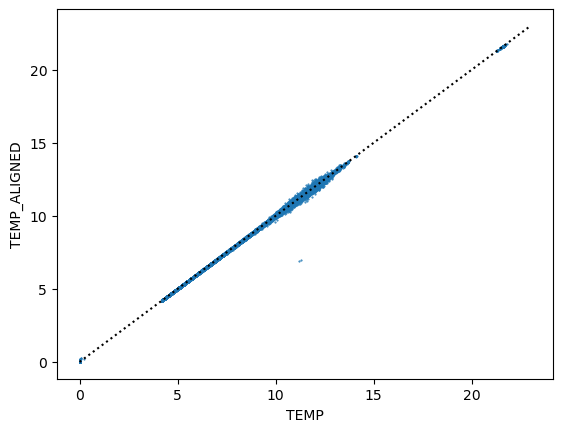

In [630]:
plt.scatter(ds.TEMP, ds.TEMP_ALIGNED, marker = ".", s = 1)
plt.plot([0, 23], [0, 23], c = "k", ls = ":")
plt.xlabel("TEMP")
plt.ylabel("TEMP_ALIGNED");

In [628]:
pd.Series(ds.TEMP_ALIGNED - ds.TEMP).describe()

count    1.928019e+06
mean     3.493752e-04
std      1.216845e-02
min     -4.345679e+00
25%     -1.528908e-03
50%      1.211763e-04
75%      1.950675e-03
max      5.718730e-01
dtype: float64

In [629]:
pd.Series(ds.PRAC_SALINITY_ALIGNED - ds.PRAC_SALINITY).describe()

count    1.927617e+06
mean    -3.250158e-06
std      1.401825e-03
min     -1.414442e+00
25%     -3.389155e-05
50%      5.060496e-08
75%      3.407315e-05
max      1.239909e-01
dtype: float64

***
# Hydrostatic pressure correction on UNCAL_PHASE_DOXY [READY]

<div class="alert alert-block alert-info">
<b>Required input:</b>
    
- UNCAL_PHASE_DOXY, i.e., uncalibrated phase, saved as `optode_pipeline_settings.uncal_phase_doxy`
- Pressure from the CTD, which has been adjusted for geometric lag
- Pressure correction coefficient, which depends on the optode type
</div>

Pressure can affect the optode's measured output in various ways. It affects the luminescence lifetime of the luminophores, quenching, and membrane O2 equilibrium level (Bittig et al., 2015a; Bittig et al., 2016). The effect on luminescence needs to be corrected on the <font color=pink> uncalibrated phase shift </font>, following Bittig et al. (2015a): 

$$UNCAL\_PHASE\_DOXY\_PCORR = UNCAL\_PHASE\_DOXY + Pcoef1 \frac{1}{1000} * PRES_{geoshift}$$

$UNCAL\_PHASE\_DOXY\_PCORR$ = Hydrostatic pressure corrected uncalibrated phase shift. 

$Pcoef1$ = Phase offset depending on the sensing foil and manufacturer, e.g., 0.1 deg per 1000 dbar for Aanderaa optodes. 

$PRES_{geoshift}$ = Pressure geometrically aligned to optode 

Note that the pressure used in this correction is the one that has been geometrically adjusted for the different locations of the optode and CTD on the glider. 

The pressure effect on quencing and on membrane O2 equilibrium level will be corrected on the oxygen concentration: MOLAR_DOXY, which is done after the salinity correction. 

<div class="alert alert-block alert-warning">
<b>Warning: </b> 
    
Pressure correction needs to be applied to the uncalibrated phase shift, _not_ the calibratd phase shift. If uncalibrated phase shift is not available, skip this hydrostatic pressure correction. 
</div>

<div class="alert alert-block alert-success">
STEP: Apply hydrostatic pressure correction on uncalibrated phase shift (UNCAL_PHASE): 
</div>

In [307]:
optode_pipeline_settings.uncal_phase_doxy_pcorr # = optode_pipeline_settings.uncal_phase_doxy + "_PCORR" # set the name for the pressure corrected uncalibrated phase shift
ds[optode_pipeline_settings.uncal_phase_doxy_pcorr] =  phase_hydrost_press_corr(UNCAL_PHASE_DOXY = ds[optode_pipeline_settings.uncal_phase_doxy], 
                                                                           PRES_geoshift = ds.PRES_ALIGNED, Pcoef1=None, optode_pipeline_settings)


'UNCAL_PHASE_DOXY_PCORR'

Hydrostatic pressure correction done with Pcoef1 =  0.1 ( aa3830 )


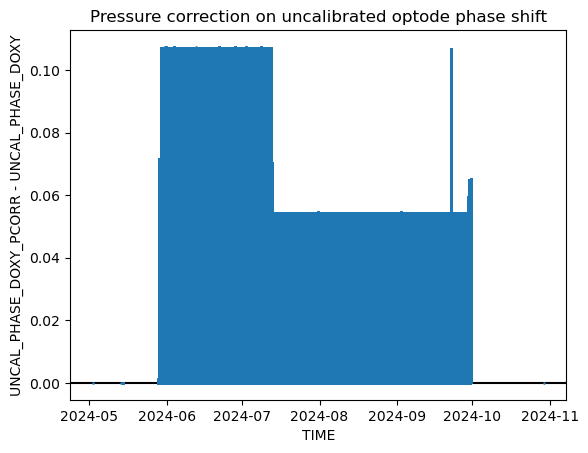

In [308]:
plt.scatter(ds.TIME, ds.UNCAL_PHASE_DOXY_PCORR - ds.UNCAL_PHASE_DOXY, marker = ".", s = 3)
plt.ylabel("UNCAL_PHASE_DOXY_PCORR - UNCAL_PHASE_DOXY")
plt.xlabel("TIME")
plt.axhline(y = 0, c = "k", zorder = 0)
plt.title("Pressure correction on uncalibrated optode phase shift");

In [309]:
pd.Series(ds.UNCAL_PHASE_DOXY_PCORR - ds.UNCAL_PHASE_DOXY).describe()

count    4.701946e+06
mean     3.628225e-02
std      2.589751e-02
min     -3.500000e-05
25%      1.583455e-02
50%      3.257498e-02
75%      4.957850e-02
max      1.073760e-01
dtype: float64

***
# Derive calibrated phase shift (CALPHASE_DOXY) [READY]

The calibrated phase shift is calculated using the uncalibrated phase shift and a 4th order polynomial function using calibration coefficients provded by the manufacturer. 

<div class="alert alert-block alert-info">
<b>Required input: </b>

- UNCAL_PHASE_DOXY_PCORR, i.e., uncalibrated phase corrected for pressure
- PhaseCoef calibration coefficients from the manufacturer
</div>

This is the temperature compensation step, converting the uncalibrated phase into a "calibrated phase". 

This step is the same for all Aanderaa optodes. 

- aa3830: BPhase (blue phase shift ) &rarr; Uncal_phase (uncalibrated phase shift) &rarr; Uncal_phase_pcorr &rarr; DPhase (calibrated phase shift)
- aa4330: C1RPhase and C2RPhase (blue and red phase shift) &rarr; TCPhase (uncalibrated phase shift) &rarr; TCPhase_Pcorr &rarr; CalPhase (calibrated phase shift)

We have aligned the naming of uncalibrated phase shifts among different optodes: UNCAL_PHASE_DOXY and UNCAL_PHASE_DOXY_PCORR. The calibrated phase shift will be named CALPHASE_DOXY. Note that this is the same as DPHASE_DOXY (Aanderaa 3830 series) and CALPHASE (Aanderaa 4330 series). 


<div class="alert alert-block alert-success">
STEP: Calculate calibrated phase (CALPHASE_DOXY) from uncalibrated phase (UNCAL_PHASE_DOXY), which has ideally been corrected for pressure (UNCAL_PHASE_DOXY_PCORR): 
</div>

In [ ]:
from calculate_dphase_aa import calculate_dphase_aa

In [310]:
print("Name for calibrated phase shift: ", optode_pipeline_settings.calphase_doxy)
# determine the calibrated phase shift
ds[optode_pipeline_settings.calphase_doxy] = calculate_dphase_aa(ds = ds, UNCAL_PHASE_DOXY_PCORR = ds[optode_pipeline_settings.uncal_phase_doxy_pcorr], cal_sheet_aa = cal_sheet_aa)

Name for calibrated phase shift:  CALPHASE_DOXY


***
# Phase shift to DO concentration (MOLAR_DOXY) [READY]

Convert CALPHASE_DOXY (i.e. calibrated phase) to MOLAR_DOXY (in umol L-1). 

<font color=orange> Note: we will call the variable MOLAR_DOXY_ADJUSTED instead of MOLAR_DOXY, to distinguish it from the MOLAR_DOXY calculated by the optode, which does not account for pressure and salinity corrections. </font> 

The way this is done is different for different optodes. Each optode also has several options. 


<div class="alert alert-block alert-warning">
<b>Careful! </b> 

For Aanderaa 4330, use the TEMP_DOXY data as input for temperature, because this temperature has been used for the determination of the calibration coefficients. Other steps need to use the CTD temperature (TEMP). 

For Aanderaa 3830, use the CTD temperature (TEMP), because this optode model has a slow response temperature sensor and using the temperature from the CTD has shown to lead to more accurate results. Subsequent processing steps also need to use the CTD temperature (TEMP). 
 
</div>




## Aanderaa 3930, 3835, 3975, 4130, and 4175 [READY]

<div class="alert alert-block alert-info">
<b>Required input:</b>
    
- CALPHASE_DOXY, i.e., calibrated phase
- Temperature: CTD temperature, shifted by geometric lag! 
- Set of foil-dependant calibration coefficients from the manufacturer
</div>


<b> Aanderaa 3830, 3835, 3930, 3975, 4130, 4175 (and also 3930?!) </b>
- Method 1: Polynomial standard calibration (polynomial_standard)
- Method 2: Stern-Volmer equation (SVU)
- Method 3: modified Stern-Volmer equation for pO2 (SVU-modified).


<div class="alert alert-block alert-warning">
<b>To do: </b> 

- [x] Replace the interpolated CTD data input with properly geometric-lag-corrected CTD data. 
- [x] Aanderaa 3830 method 1
- [x] Aanderaa 3830 method 2
- [ ] Aanderaa 3830 method 3 (low priority - to be done in the future)
- [x] Change MOLAR_DOXY name when calculated in this pipeline to MOLAR_DOXY_ADJUSTED to distinguish MOLAR_DOXY calculated by the optode!
</div>

### Polynomial method [READY]

<div class="alert alert-block alert-success">
STEP: Convert calibrated phase shift to oxygen concentration (MOLAR_DOXY): 
</div>

In [321]:
# For Aanderaa 3930, 3835, 3975, 4130, and 4175
ds["MOLAR_DOXY_ADJUSTED"] = calphase_to_molar_doxy_aa38(CALPHASE_DOXY = ds[optode_pipeline_settings.calphase_doxy], T = ds.TEMP_ALIGNED, cal_sheet_aa = cal_sheet_aa, method = "poly")


Note: Make sure input temperature is CTD temperature (ideally adjusted for geometric lag)!


## Aanderaa 4330, 4831, 4835 [READY]

<div class="alert alert-block alert-info">
<b>Required input:</b>

- CALPHASE_DOXY, i.e., calibrated phase
- Temperature: optode temperature! (TEMP_DOXY)
- Set of foil-dependant calibration coefficients from the manufacturer
- Salinity (only required for certain methods)
</div>

For Aanderaa 4330, 4831, and 4835, the phase shift is converted into a molar concentration of oxygen (i.e., MOLAR_DOXY in umol L-1) in 3 ways, depending on whether the SVUFoilCoefs have been made available by the manufacturer. 

<b>Method 1 (and 2): Polynomial standard calibration </b>


<b>If the SVUFoilCoefs are unavailable </b>, MOLAR_DOXY is calculated from the oxygen solubility (cm3 / dm3; determined from Garcia & Gordon, 1992) and from percentage air saturation: 

$$C^\ast = exp [A_0 + A_1 * T_S + A_2 * T_S^2 + A_3 * T_S^3 + A_4 * T_S^4 + A_5 * T_S^5 + S * (B_0 + B_1 * T_S + B_2 * B_S^2 + B_3 * T_S^3) + C_0 * S^2]$$

, where 

$A_0$ - $A_5$ and $B_0$ - $B_3$ and $C_0$ are constants from Garvia & Gordon (1992), S is salinity, and $T_S$ is scaled temperature: 

$$T_S = ln(\frac{298.15 - t}{273.15 - t})$$

, where t is temperature in degC. <font color=orange> Note, use TEMP_DOXY </font> 

This method can be followed up by a linear 2-point adjustment, usually applied to Aanderaa optodes 4330 with serial number >= 1000. (Method 2)


<b>Method 3 (and 4): Stern-Volmer equation </b>

<b>If the SVUFoilCoefs are available</b>, apply the Stern/Volmer/Uchida formula: 

$$MOLAR\_DOXY = \frac{\frac{P_0}{P_c}-1}{K_{SV}}$$

, where 

$$K_{SV} = c_0 + c_1 * T + c_2 * T^2$$ 

$$P_0 = C_3 + C_4 * T $$

$$P_c = c_5 + c_6 * DPHASE\_DOXY\_Pcorr$$

, and T is temperature in degC. <font color=orange> Note, use TEMP_DOXY. </font> 

This method can be followed up by a linear 2-point adjustment, usually applied to Aanderaa optodes 4330 with serial number >= 1200. (Method 4)

<b>Method 5: modified Stern-Volmer equation </b>

This method follows Bittig et al. (2018), which calculates pO2 (partial pressure of O2) directly, which mean no salinity adjustment is necessary. 


<b> Aanderaa 4330, 4835, 4831 </b>
- Method 1: Polynomial standard calibration (polynomial_standard)
- Method 2: Standard calibration followed by 2-point adjustment (polynomial_standard-2point). Have merged this with method 1! 
- Method 3: Stern-Volmer equation (SVU)
- Method 4: Stern-Volmer equation followed by 2-point adjustment (SVU-2point). Haver merged this with method 3!
- Method 5: modified Stern-Volmer equation for pO2 (SVU-modified)

<div class="alert alert-block alert-warning">
<b>To do: </b> 

- [ ] Replace the interpolated CTD data input with properly geometric-lag-corrected CTD data. 
- [x] Aanderaa 4330 method 1
- [x] Aanderaa 4330 method 2 (merged with method 1)
- [x] Aanderaa 4330 method 3
- [x] Aanderaa 4330 method 4 (merged with method 3)
- [ ] Aanderaa 4330 method 5 (low priority)

</div>

<div class="alert alert-block alert-success">
STEP: Convert calibrated phase shift (CALPHASE) to oxygen concentration (MOLAR_DOXY): 
</div>

In [338]:
# For Aanderaa 4330, 4831, 4835

ds["MOLAR_DOXY_ADJUSTED"] = calphase_to_molar_doxy_aa43(CALPHASE_DOXY = ds[optode_pipeline_settings.calphase_doxy], T = ds["TEMP_DOXY"], S = ds["PRAC_SALINITY_ALIGNED"], cal_sheet_aa = cal_sheet_aa)



***
# Salinity correction [READY]

<div class="alert alert-block alert-info">
<b>Required input: </b>
    
- Salinity (geometric-lag adjusted)
- Temperature (geomatric-lag adjusted)
- MOLAR_DOXY(_ADJUSTED)
</div>

The MOLAR_DOXY value determined by the optode assumes salinity = zero. The salinity correction is applied as follows: 

$$
c_{\mathrm{O_2,adj}}^{S} =
\frac{1013.25 - p_{\mathrm{H_2O}}(\vartheta, 0)}
     {1013.25 - p_{\mathrm{H_2O}}(\vartheta, S)}
\; S_{\mathrm{Corr}} \;
c_{\mathrm{O_2,adj}}^{0}
$$


where:

- $c_{\mathrm{O_2,adj}}^{S}$ is MOLAR_DOXY_PSAL

- $c_{\mathrm{O_2,adj}}^{0}$ is MOLAR_DOXY_ADJUSTED

- $p_{\mathrm{H_2O}}(\vartheta, S)$ is the **water vapor pressure**, which depends on temperature and salinity (Weiss & Price, 1980).

- $S_{\mathrm{Corr}}$ is the **salinity-dependent $O_{2}$ solubility correction factor**, calculated following Garcia & Gordon (1992) using the Benson & Krause refit.


The correction factor $S_{\mathrm{Corr}}$ is computed from scaled temperature $T_s$ as:

$$
S_{\mathrm{Corr}} =
\exp\left[
(S - S_{\mathrm{preset}})\left(
B_0 + B_1 T_s + B_2 T_s^2 + B_3 T_s^3
\right)
+ C_0 \left(S^2 - S_{\mathrm{preset}}^2\right)
\right]
$$

with:

- Scaled temperature:  
  $$
  T_s = \ln\left(\frac{298.15 - T}{273.15 + T}\right)
  $$

- Salinity used by the optode calibration: $S_{\mathrm{preset}}$  
  (often **35** for glider processing, but we will use the geometrically shifted salinity measured by the CTD on the glider)

<div class="alert alert-block alert-success">
STEP: Apply salinity correction: 
</div>

In [343]:
T = ds.TEMP_ALIGNED
S = ds.PRAC_SALINITY_ALIGNED
MOLAR_DOXY = ds["MOLAR_DOXY_ADJUSTED"]
ds["MOLAR_DOXY_PSAL"] = apply_salinity_correction(MOLAR_DOXY, T, S, Spreset = 0)


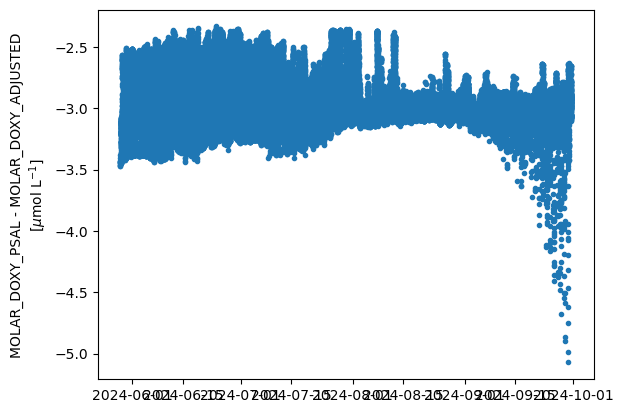

In [353]:
plt.scatter(ds.TIME, ds.MOLAR_DOXY_PSAL - ds.MOLAR_DOXY_ADJUSTED, marker = ".");
plt.ylabel("MOLAR_DOXY_PSAL - MOLAR_DOXY_ADJUSTED\n[$\mu$mol L$^{-1}$]");

***
# CALPHASE_DOXY to pO2 [NOT WRITTEN]

Bittig et al. (2016) suggest that the salinity correction can be skipped when accounting for the O2-T response using a different mathematical model that determines the oxygen output in terms of partial pressure (pO2) instead of molar concentration (MOLAR_DOXY) (Uchida et al., 2010). pO2 is independent of salinity, and thus a salinity correction is not applicable. pO2 can then be converted to MOLAR_DOXY, using the SCOR WG 132 recommendations for convertions. 

<div class="alert alert-block alert-warning">
<b>Low priority</b> 

Will implement the possibility of this step at a later stage. 
</div>

***
# Hydrostatic pressure correction [READY]

<div class="alert alert-block alert-info">
<b>Required input: </b>

- MOLAR_DOXY_PSAL, i.e., salinity-corrected oxygen concentration (umol L-1)
- Pressure from CTD that has been corrected for geometric lag (dbar)
</div>

Correct for hydrostatic pressure correction on quenching and membrane O2 equilibrium. The pressure effect on oxygen quenching is corrected by applying a multiplicative factor to the salinity-corrected oxygen concentration:

$$
\mathrm{MOLAR\_DOXY\_{PSAL\_PCORR}} =
\mathrm{MOLAR\_DOXY\_{PSAL}} \times
\left[
1 +
\left( P_{\mathrm{coef2}} \, T + P_{\mathrm{coef3}} \right)
\frac{\mathrm{P}}{1000}
\right]
$$

where:

- $T$ is the CTD temperature (°C), ideally adjusted for geometric lag 
- $\mathrm{P}$ is the pressure (dbar), ideally adjusted for geometric lag 
- $P_{\mathrm{coef2}}$ and $P_{\mathrm{coef3}}$ are empirical pressure-response coefficients  

The correct set of coefficients depends on whether **BPhase / TCPhase**, i.e., uncalibrated phase shift, has already been corrected for the pressure effect.

1. If uncalibrated phase shift *has been corrected* for pressure ($P_{\mathrm{coef1}} = 0.1$):

$$
P_{\mathrm{coef2}} = 2.2 \times 10^{-4}, \qquad
P_{\mathrm{coef3}} = 4.19 \times 10^{-2}
$$

2. If BPhase / TCPhase *has NOT been corrected* for pressure ($P_{\mathrm{coef1}} = 0$):

$$
P_{\mathrm{coef2}} = 2.5 \times 10^{-4}, \qquad
P_{\mathrm{coef3}} = 3.28 \times 10^{-2}
$$

<div class="alert alert-block alert-warning">
<b>To do: </b> 

- [x] Incorporate Argo: Thierry et al., 2025a p 28-29.
- [x] Check units of Pcoefs and pressure
</div>



<div class="alert alert-block alert-success">
STEP: Apply second pressure correction: 
</div>

In [370]:
MOLAR_DOXY_PSAL = ds.MOLAR_DOXY_PSAL
P = ds.PRES_ALIGNED
T = ds.TEMP_ALIGNED
ds["MOLAR_DOXY_PSAL_PRES"] = DO_hydrost_press_corr_aa(MOLAR_DOXY_PSAL, P, T, optode_pipeline_settings)

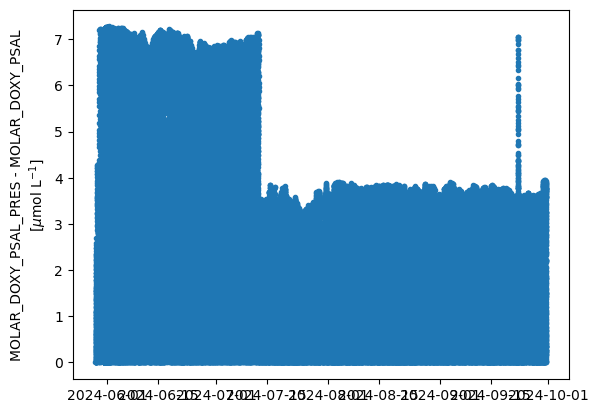

In [371]:
plt.scatter(ds.TIME, ds.MOLAR_DOXY_PSAL_PRES - ds.MOLAR_DOXY_PSAL, marker = ".");
plt.ylabel("MOLAR_DOXY_PSAL_PRES - MOLAR_DOXY_PSAL\n[$\mu$mol L$^{-1}$]");

Combined effect of pressure and salinity adjustment on MOLAR_DOXY_ADJUSTED: 

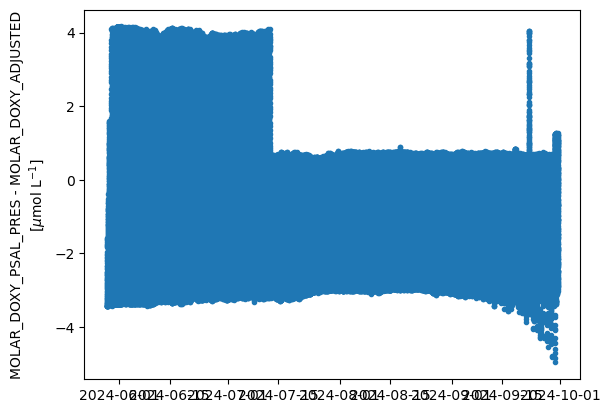

In [367]:
plt.scatter(ds.TIME, ds.MOLAR_DOXY_PSAL_PRES - ds.MOLAR_DOXY_ADJUSTED, marker = ".");
plt.ylabel("MOLAR_DOXY_PSAL_PRES - MOLAR_DOXY_ADJUSTED\n[$\mu$mol L$^{-1}$]");

---
# Conservative temperature [NOT WRITTEN]

<font color=orange> Am still investigating whether conservative temperature is necessary to calculate oxygen saturation (and density). Consider this later. </font>

***
# MOLAR_DOXY to DOXY [IN PROGRESS]

Convert MOLAR_DOXY (umol L-1) to DOXY (umol kg-1), following SCOR WG 142 recommendations. 


<div class="alert alert-block alert-warning">
<b>To do: </b> 

- [ ] Potential density calculation: I cannot find method based on Fofonoff and Millard (1983). Using teos10 at the moment. 
</div>


- Fofonoff & Millard (1983): https://unesdoc.unesco.org/in/documentViewer.xhtml?v=2.1.196&id=p::usmarcdef_0000059832&file=/in/rest/annotationSVC/DownloadWatermarkedAttachment/attach_import_1f50d5aa-4059-4840-859b-b61e75310763%3F_%3D059832engb.pdf&locale=en&multi=true&ark=/ark:/48223/pf0000059832/PDF/059832engb.pdf#%5B%7B%22num%22%3A248%2C%22gen%22%3A0%7D%2C%7B%22name%22%3A%22XYZ%22%7D%2C-242%2C846%2C0%5D
- Millero et al. (1980): https://www.sciencedirect.com/science/article/pii/0198014980900163 

In [ ]:
def calculate_potential_density_unesco(S, T): 
    """
    Calculate potential density of seawater (kg L-1) referenced to a hydrostatic pressure of 0 dbar and using practical salinity.
    Bittig et al. (2016) recommends using equation of state based on Fofonoff and Millard (1983) and Millero et al. (1980). 
    Potential density at 0 dbar and potential temperature. 

    ARGS: 
        T : array-like, float
            Temperature in degrees Celsius
        S : array-like, float
            Practical salinity 

    RETURN: 
        rho : potential density of seawater in kg L-1. 
    """


    

    return rho

<div class="alert alert-block alert-success">
STEP: Convert MOLAR_DOXY to DOXY: 
</div>

In [378]:
ds["DOXY"] = o2_umolL_to_umolkg(MOLAR_DOXY = ds.MOLAR_DOXY_ADJUSTED, T = ds.TEMP_ALIGNED, S = ds.PRAC_SALINITY_ALIGNED, lon = ds.LONGITUDE, lat = ds.LATITUDE)


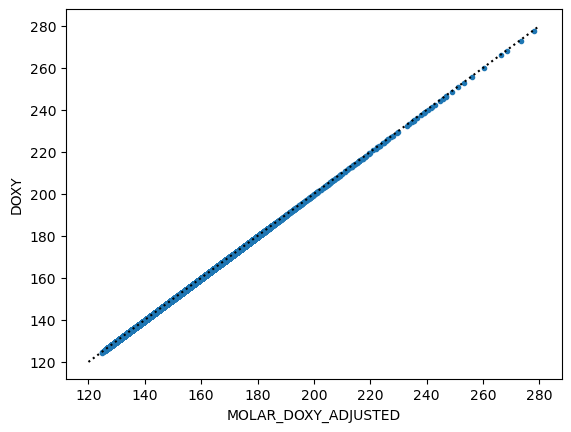

In [382]:
plt.scatter(ds.MOLAR_DOXY_ADJUSTED, ds.DOXY, marker = ".")
plt.plot([120, 280], [120, 280], c = "k", ls = ":")
plt.xlabel("MOLAR_DOXY_ADJUSTED")
plt.ylabel("DOXY"); 

***
# Tests [IN PROGRESS]

<font color=pink> These tests need to be done on oxygen in umol kg-1. </font> 


<div class="alert alert-block alert-warning">
<b>To do:  </b> 

- [ ] Functions do not yet properly adapt the QC of the variable. Needs to be checked with what Dan has already written for the pipeline. 
</div>

___
## Global range check [IN PROGRESS]

Global range check for DOXY and TEMP_DOXY: 

- -5 < DOXY < 600
- -2.5 < TEMP_DOXY < 40


<div class="alert alert-block alert-warning">
<b>Already in toolbox </b> 

See test in standard_pipeline.yml. 
</div>


In [ ]:
import global_range_check

<div class="alert alert-block alert-success">
STEP: global range check: 
</div>

___
## Regional range check [IN PROGRESS]

Flag temperatures outside **region-specific valid ranges** as 4 (bad):  
- Red Sea: 21.7 – 40.0 °C  
- Mediterranean Sea: 10.0 – 40.0 °C  

<div class="alert alert-block alert-warning">
<b> To do: </b>

- [ ] Check with Dan whether regional range check can be implemented on general level. Not sure it's relevant for other variable pipelines.  
</div>

In [385]:
from matplotlib.path import Path
import regional_range_check 

<div class="alert alert-block alert-success">
STEP: regional range check: 
</div>

---
## Outlier and spike check [IN PROGRESS]

Spike detection test for `DOXY` or `TEMP_OXY` measurements using surrounding points to identify sudden outliers.


$$
\text{Test value} = \Big| V_2 - \frac{V_3 + V_1}{2} \Big| - \Big| \frac{V_3 - V_1}{2} \Big|
$$

where:  
- `V2` is the measurement being tested,  
- `V1` and `V3` are the measurements immediately above and below.  

Flags a value as **bad (QC = 4)** if the test value exceeds **pressure-dependent thresholds**:  

- **DOXY:**  
  - P < 500 dbar → test value > 50 µmol/kg  
  - P ≥ 500 dbar → test value > 25 µmol/kg  

- **TEMP_OXY:**  
  - P < 500 dbar → test value > 6 °C  
  - P ≥ 500 dbar → test value > 2 °C  



<div class="alert alert-block alert-warning">
<b>Already in toolbox </b> 

See test in standard_pipeline.yml. 
</div>

In [ ]:
import spike_check

<div class="alert alert-block alert-success">
STEP: outlier and spike check: 
</div>

---
## Gradient test [IN PROGRESS]

Gradient test for `DOXY` or `TEMP_OXY` measurements using surrounding points to identify sudden outliers.


$$
\text{Test value} = \Big| V_2 - \frac{V_3 + V_1}{2} \Big| 
$$

where:  
- `V2` is the measurement being tested,  
- `V1` and `V3` are the measurements immediately above and below.  

Flags a value as **bad (QC = 4)** if the test value exceeds **pressure-dependent thresholds**:  

- **DOXY:**  
  - P < 500 dbar → test value > 50 µmol/kg  
  - P ≥ 500 dbar → test value > 25 µmol/kg  

- **TEMP_OXY:**  
  - P < 500 dbar → test value > 9 °C  
  - P ≥ 500 dbar → test value > 3 °C  



<div class="alert alert-block alert-warning">
Check with Dan whether gradient test can be implemented on general level. Not sure it's relevant for other variable pipelines.  
</div>

In [4]:
from gradient_test import gradient_test

<div class="alert alert-block alert-success">
STEP: gradient check: 
</div>

___
## Digit roll over test [NOT WRITTEN]

From Thierry et al. (2025) - Argo quality controls: 

"Only so many bits are allowed to store temperature values in a profiling float. This range is not always large enough to accommodate conditions that are encountered in the ocean. When the range is exceeded, stored values rollover to the lower end of the range. This rollover should be detected and compensated for when profiles are constructed from the data stream from the float.
This test is used to make sure the rollover is properly detected:

- TEMP_DOXY difference between adjacent pressures > 10 °C.


Action: When a rollover is detected, both values used to detect the jump in the data should be flagged with a QC = ‘4’, other values of the profile with a QC = ‘3’."

<div class="alert alert-block alert-warning">
Check with Dan whether digit roll over test can be implemented on general level. Not sure it's relevant for other variable pipelines.  
</div>

<div class="alert alert-block alert-success">
STEP: digit roll over test: 
</div>

___
## Stuck value test [NOT WRITTEN]

From Thierry et al. (2025) - Argo quality controls: 

"This test looks for all biogeochemical sensor outputs (i.e. ‘i’ and ‘b’ parameter measurements transmitted by the float) in a vertical profile being identical.

Action: Stuck values should be flagged as bad data (QC = ’4’)." 


<div class="alert alert-block alert-warning">
<b>Already in toolbox </b> 

See test in standard_pipeline.yams. 
</div>

<div class="alert alert-block alert-success">
STEP: stuck value test: 
</div>

___
## Frozen profile test [NOT WRITTEN]

<font color=orange> Unsure whether this is relevant for gliders. </font> 

From Thierry et al. (2025) - Argo quality controls: 


"This test is used to detect a float that reproduces the same profile (with very small deviations) over and over again.
Typically the differences between two profiles are of the order of 0.01 °C for temperature.
- A). Derive TEMP_DOXY profiles by averaging the original profiles to get mean values for each profile in 50 dbar slabs (TEMP_DOXY_prof, TEMP_DOXY_previous_prof). This is necessary because the floats do not sample at the same level for each profile.
- B). Obtain absolute values of the difference between the averaged temperature profiles as follows:
  - delta_TEMP_DOXY = abs(TEMP_DOXY_prof - TEMP_DOXY_previous_prof)
- C). Find the maximum, minimum and mean of the absolute values of the averaged differences between profiles for temperature:
        - max(delta_TEMP_DOXY), min(delta_TEMP_DOXY), mean(delta_TEMP_DOXY)
- D). To fail the test, require that:
    - max(delta_TEMP_DOXY) < 0.3 °C
    - min(delta_TEMP_DOXY) < 0.001°C
    - mean(delta_TEMP_DOXY) < 0.02 °C

Action: If a profile fails this test, all measurements from the profile are flagged as bad data (QC = ‘4’). If a float fails this test on 5 consecutive cycles, it is inserted in the grey list.
"

<div class="alert alert-block alert-success">
STEP: frozen profile test: 
</div>

___
## Gross temperature sensor drift [NOT WRITTEN]

From Thierry et al. (2025) - Argo quality controls: 


"This test is implemented to detect a sudden and significant sensor drift. It calculates the average temperature from the deepest 100 dbar of a profile and the previous good profile. Only measurements with good QC are used.

Action: For TEMP_DOXY, if the difference between the two average values is more than 1 °C, then all TEMP_DOXY values from the profile are flagged as probably bad data (QC = ‘3’).""

<div class="alert alert-block alert-success">
STEP: gross temperature sensor drift test:  
</div>

___
## Bad P/T/S QC spreading

<font color=orange>!!!  Careful! We use the geometrically aligned CTD data to calculate oxygen. These aligned CTD data have been interpolated. How can we assess their QC?? </font> 

DOXY_QC should be 4 when:
- PRES_QC = 4
- TEMP_QC = 4
- TEMP_DOXY_QC = 4 AND TEMP_DOXY is actually used in determination of MOLAR_DOXY i.e., when sensor is one of the Aanderaa4330 series. 

DOXY_QC should be 3 when: 
- PRAC_SALINITY_QC = 4


<div class="alert alert-block alert-warning">
<b>Already in toolbox </b> 

See test in standard_pipeline.yams. 
</div>


<div class="alert alert-block alert-warning">
<b>To do:  </b> 

- [ ] How to apply these QC spreading for geometrically shifted CTD data?
- [ ] These oxygen QCs are relevant to 
</div>

<div class="alert alert-block alert-success">
STEP: QC spreading: 
</div>

***
# Response lag correction to phase [IN PROGRESS]

A sensor response correction is necessary for the following reasons: 

- Dissolved oxygen needs to diffuse across the optode membrane. The diffusion rate is strongly dependent on water temperature and the thickness of the foil (membrane).
- Dissolved oxygen also needs to diffuse across the boundary layer above the membrane, which is also temperature dependent and additionally depends on water flow. The latter can be determined from the sensor position on the glider, glider speed and/or angle of attack.

The response lag correction needs to be applied to both the optode phase *and* the optode temperature. **Check if optode temperature or CTD temperature is used!!** Accurate time stamps of the recorded optode time is also required. 

Source: https://github.com/OceanGlidersCommunity/Oxygen_SOP/blob/main/sections/oxygen_dmqc.md 

There is no one way for sensor response lag correction that the entire community agrees on; there is no "best practice". Different groups have used their own methods, which are summarised here. 

____
__Time response correction 1 - GEOMAR__
This method was developed by Johannes Hahn and Henry Bittig, specifically for moored and glider Aanderaa optodes. 

- Does not include a geometric lag correction, but encourages to do so before applying the tiem response correction.
- The method includes 2 delay time constants.
    - The first one estimates the temperature of the optode foil based on the CTD temperature.
    - The second one describes the optode response time due to changing oxygen concentrations, i.e., the diffusion rate across the boundary layer above the membrane as well as across the foil membrane.
- Make sure to only apply optimisation to up-down pairs that have not been affected by bio-fouling. 

1. Linearly intepolate the following variables onto 1 sec grid: optode phase, optode temp, CTD temp, pressure, salinity. This avoids issues from different measurement times.
2. A set of foil temperatures is estimated by applying an exponential filter to the CTD temp with time scales between 10 to 50 sec in steps of 5 sec. This creates different "virtual" foil temperatures. <font color=orange> Isn't this the same as the geometric lag correction?? Only when the optode temp responds as fast as teh CTD temp. Otherwise, the optode temp needs to be corrected for both the geometric lag as well as its slow response time. First the CTD data needs to be aligned with the optode data in time and space, and then the optode data needs to be corrected for the response lag. </font>
3. Calculate the oxygen concentrations using each virtual foil temperature in the set of virtual foil temperatures.
4. Apply a reverse exponential filter with timescales between 0-200 sec in steps of 20 s to each oxygen concentration. This creates sets of oxygen profiles. <font color=lightblue> ["Reverse", because we're trying to get the 'true' O2 from measured O2. "Exponential" because the response of the sensor is diffusion-driven equilibration, which follows first-order kinetics, the solution of which is exponential.] </font>

<font color=lightblue> The reverse exponential filter should probably take the form of a recursive equation, which handles irregular sampling naturally and is also what Hahn et al. (2014) use. "Recursive" because it explicitly uses the previous sample (yi-1) and is computed step-by-step. The recursive form starts from the exact exponential response model (rather than deriving the "unknown" from differences between timesteps, i.e., the derivative). </font>

$$
x_i =
\frac{
y_i - \alpha_i y_{i-1}
}{
1 - \alpha_i
}
$$

where

$$
\alpha_i = \exp\left(-\frac{\Delta t_i}{\tau}\right)
$$

and

$$
\Delta t_i = t_i - t_{i-1}.
$$

<font color=lightblue> Alternatively, could also use a derivative, but it tends to increase noise when subsequent samples are not collected at high frequency or at irregular frequencies, because it starts from an estimated derivative, which can thus overestimate noise. When timesteps are small, the recursive and derivative solutions would almost be identical. </font>


5. Filter each set of oxygen concentration profiles with a forward-backward filter to remove noise created by reverse filtering. 40 sec is the fixed time constant that has been used for this filter, but this can be adapted according to whether fast or slow foils are used. <font color=lightblue> [The forward-backward filter removes the artificial time shift when smoothening data. It first filters/smoothened forward, then you reverse the order of the output data, apply the filter/smoothening again, and finally reverse the order of the output data again. This cancels out the artificial time shifts introduced by the filtering] </font>
6. Grid all concentrations to a 1 dbar grid: first bin and then linearly interpolate to the full dbar.
7. Calculate the differences between all up and down cast pairs and sum them within each of the concentration sets.
8. Determine the delay pair (i.e. the CTD temp delay for virtual foil temperare and the optode response delay) that has the smallest difference sum. Apply this to the entire deployment. Typical best delays are CTD-temp between 30-100 s and optode response between 20-50 s. 


<font color=orange> Find ref: Krahmann2021 </font>

____
__Time response correction 2 - IMOS__
This method was developed by Mun Woo for IMOS (Slocum) glider toolbox. 

- Up- and down-casts are compared in pressure space
- Applies a time-shift and no exponential filter
- Time-shift values are determined per dive and a rolling median is used to exclude dives with particularly high/low values. [this is for the geometric alignment]
- Advantage: noise is not amplified [geometric alignment]
- Be aware: second order effects are not removed

First, determine the geometric lag based on average pitch and average vertical speed per cast (see section on Geometric Alignment!). The geometric lag is passed through a low-pass filter (i.e., allows low frequencies to pass through and suppresses high frequency variability), which avoids extreme values. 

The following steps to correct for the diffusive lag are applied only after the geometric time lag has been corrected. 

1. Calculate the median RMS difference and bias between up and down casts over a possible range of time lag/shift values between 0 - 40 seconds for each dive.
2. Apply the time shift with the smalles median RMS difference to the optode phase
3. Calculate the oxygen concentration with the corrected phase and CTD (or optode) temperature, using the factory foil coefficients. 

<font color=orange> Find ref: WooGourcuff2021 </font>
____
__Time response correction 3 - UEA__
This method was developed by Bastien Queste and is used in the UEA Seaglider toolbox. 

1. Align CTD temperature based on flight speed to the optode phase. This method uses a 1-D interpolation and a flight speed dependent time shift [see the dynamic geometric alignment]
2. Calculate the oxygen partial pressure directly from the optode phase and the time shifted optode temperature. <font color=orange> This requires a refit of the manufacturer multi-point calibration. Perhaps the pO2 can also be calculated via the molar oxy, as has already been coded? </font>
3. In pressure or density space, compare the up and down profiles and apply one of the following two methods:
    - Use a shoelace algorithm to minimize area between the curves
    - Calculate the RMSD from vertically binned data
4. Use a minimization algorithm (fminsearch) to fit two lag coefficients as per Hahn2014: τ = τ0+τ1(T−20). This is done per dive. 
5. Per dive, use the resulting τ with an exponential inverse-filter on the optode phase. It could also be applied to pO2.
6. Re-calculate the oxygen concentration using the corrected phase and aligned CTD temperature OR corrected optode temperature using factory foil coefficients.




____
__Time response correction 4 - AlterEco__

Use when data is only collected on either the up- or down-cast; i.e., glider only recorded data on either the up- or down-cast. It combines the geometric lab and the diffusive lag. 

1. Calculate the lag by minimising the difference between the CTD and optode temperatures.
2. Use the result in an inverse-filter for the optode phase and temperature. <font color=orange> I think steps 1 and 2 are the geometric lag correction? </font>
3. Applies secondary lag correction based on temperature from the UEA toolbox and Hahn et al. (2014) <font color=orange> I don't understand this part. Is this just referring to steps 3-5? </font>
4. Calculate oxygen concentrations using the corrected phase and optode temperature and factory foil coefficients. 


____


To start with, we will implement the ... method, and design the code so we or the community can add other methods at a later point. 


<div class="alert alert-block alert-info">
<b>Required input:</b>
    
- optode phase or glider_direction that indicates which data are from the down or up cast 
- optode temperature: either optode temp or CTD temp - clarify! 
- optode time

</div>

<font color=orange> Need a way of identifying up-down pairs! </font> 

In [ ]:
from scipy.interpolate import interp1d
from scipy.signal import medfilt

## Hahn2014

In [ ]:
def response_lag_corr_hahn2014(time, phase, temperature, tau_DO):
    """
    Apply an optode response lag correction to optode phase data according to Hahn 2014. 
    This code is based on gt_sg_sensors_aa4330 from UEA_Seaglider_Toolbox. 
    Note: Safest to use optode temperature rather than CTD temperature to avoid geometric lag effects
    between optode and CTD. 
    This lag correction is designed for a "standard" optode foil. Do not apply this lag correction 
    for a fast optode. 

    ARGS:
        time : array-like
            Time array [days or datetime64], same length as tphase.
        tphase : array-like
            Measured optode phase values. 
        temperature : array-like
            Optode temperature in °C (used for temperature-dependent tau). 
        tau_DO : tuple or list
            Two coefficients [tau0, tau1] for sensor lag (s) as per Hahn correction:
            tau = tau0 + tau1 * (T - 20)
    
    RETURN: 
        tphase_corrected : ndarray
            Lag-corrected phase values, same length as input.

    Sources: 
        Hahn 2014
    """

    # Convert time to seconds relative to start
    time_s = (time - time[0]) * 24 * 60 * 60  # assuming 'time' in days
    time_s = np.asarray(time_s)

    # Compute temperature-dependent tau (Hahn 2014)
    tau = tau_DO[0] + tau_DO[1] * (temperature - 20)

    # Define high-resolution (1 Hz) time grid
    time_hr = np.arange(time_s[0], time_s[-1], 5)  # 5 s spacing (~0.2 Hz)
    
    # Optional simple filtering (replace with e.g. medfilt if desired)
    def smooth(x, kernel_size=3):
        return medfilt(x, kernel_size=kernel_size)

    # Interpolate to high-resolution grid
    phase_hr = np.interp(time_hr, time_s, smooth(phase))
    tau_hr = np.interp(time_hr, time_s, smooth(tau))

    # Preallocate corrected phase array
    phase_new = np.copy(phase_hr)

    # Apply stepwise lag correction (recursive form)
    for j in range(1, len(phase_hr)):
        dt = time_hr[j] - time_hr[j - 1]
        exp_factor = np.exp(-dt / tau_hr[j - 1])
        numerator = phase_hr[j] - phase_hr[j - 1] * exp_factor
        denominator = 1 - exp_factor
        phase_new[j] = numerator / denominator

    # Downsample back to original timestamps
    interp_func = interp1d(time_hr, phase_new, bounds_error=False, fill_value="extrapolate")
    phase_corrected = interp_func(time_s)

    dict_idata["PHASE_lagcorr"] = phase_corrected


***
# Storage drift correction: 2-point calibrations

<div class="alert alert-block alert-warning">
<b>To do: </b> 

- This might have to be done on phase level or given the option to do at phase or at conc level.
- Check with IMOS and Argo

</div>

***
# Unit conversions [READY]

Unit conversions follow the recommendations by the SCOR Working Group 142 (Bittig et al., 2016). 

<div class="alert alert-block alert-warning">
<b>To do: </b> 

- [x] Convert SCOR WG 142 matlab code to python 

</div>

## Molar concentration to partial pressure

In [387]:
from oxygen_conversions import o2c_to_o2p

## Molar concentration to saturation

In [387]:
from oxygen_conversions import o2c_to_o2s

## Partial pressure to oxygen concentration

In [387]:
from oxygen_conversions import o2p_to_o2c

## Partial pressure to saturation

In [387]:
from oxygen_conversions import o2p_to_o2s

## Saturation to molar concentration

In [387]:
from oxygen_conversions import o2s_to_o2c

## Saturation to partial pressure

In [387]:
from oxygen_conversions import o2s_to_o2p

***
# Validation with ship CTD casts

<div class="alert alert-block alert-warning">
<b>Low priority</b> 

Will be done at a later stage and might even have to appear in a different part of the pipeline. 
</div>

:)